# Integrated Mammogram Localization + Classification
## Dual-loss LesionFields localizers (CLEAN_V2 + size-balanced multiscale squared error, ensembled) and dual-loss ImageTokenClassifier (phenotype objective + class-balanced Brier, ensembled)

This notebook keeps the data pipeline, patient-level partitions, preprocessing, descriptor recovery and the phenotype objective of the uploaded *Integrated LesionFields CLEAN_V2 + Phenotype classifier* notebook, and changes the experiment as follows.

### A. Localization (hit rate computed as in the earlier localizer notebook)
| Model | Loss | Role |
|---|---|---|
| **A** | CLEAN_V2: soft 15x15 targets, weighted BCE (positive weight 10), asymmetric Tversky (FP 0.3, FN 0.7), lesion-centred peak loss (radius 24 px, scheduled 0 / 0.1 / 0.2 / 0.3) | first localizer |
| **B** | **Size-balanced multiscale squared error** (below) | second localizer, trained again from the same data with the new loss |
| **ENS** | probability-level average of A and B (weights configurable) | final localizer used by the classifier |

**New localization loss.** With p the predicted lesion probability, y the ground-truth mask, e = p - y and W the lesion-size / background balancing weights (pixels of a small lesion weigh more than pixels of a large one, each pixel of a lesion of area a has weight 1/sqrt(a), background pixels have weight 1/sqrt(background area)), the per-image, per-lesion-type loss is

$$L_{loc}=\frac{\lVert W(p-y)\rVert_2^2+\lVert G_1[W(p-y)]\rVert_2^2+\lVert G_3[W(p-y)]\rVert_2^2}{K+1}$$

with G1, G3 Gaussian smoothing (sigma = 1 and 3 px) and K the number of annotated lesions of that type. It is averaged over images and the mass / calcification outputs. It is a size-balanced multiscale squared error, not claimed as novel.

**Hit rate.** Two numbers are reported for A, B and ENS on validation and test, always with the same 24-px dilated lesion mask: *hit@1* (global arg-max of the union map, as in the uploaded notebook) and the *hit rate with Gaussian peak smoothing* whose sigma is chosen on validation from {0, 3, 5, 8, 12, 16} (as in the earlier localizer notebook). Dice uses a threshold chosen on validation.

### B. Classification (image level, the supplied ImageTokenClassifier)
Mammogram + high-pass image -> conv stem -> 24x16 appearance tokens + three predicted-localization statistics (mean mass, mean calcification, maximum lesion probability from the localizer **ensemble**) + 2-D coordinates -> 4 learned latent queries (4-head cross-attention with bounded localization bias) -> 1 diagnostic query -> concatenation with the global token -> MLP -> sigmoid.

| Model | Loss |
|---|---|
| **C-pheno** | phenotype objective first: weighted BCE + 0.5 attribute + 0.1 pair + 0.1 orthogonality (image-level adaptation, see sections 10 and 19) |
| **C-brier** | class-balanced Brier loss, then evaluated alone |
| **C-ens** | average of the two probabilities |

Checkpoints are selected by validation ROC-AUC with early stopping. The decision threshold is the value in {0.01, ..., 0.99} that maximises validation balanced accuracy. Metrics: ROC-AUC, average precision (AP), sensitivity, specificity, F1, balanced accuracy, Brier score, ECE (10 bins) and the confusion matrix, plus a patient-level bootstrap interval for ROC-AUC.

**Run in order on a Colab GPU.** Inspect the registration overlays before training. Test data are touched once, in the last cells, after every checkpoint, sigma, threshold and ensemble choice is frozen on validation.

In [2]:
# 1. Environment and Drive mount
import sys, subprocess, importlib.util
if importlib.util.find_spec('google.colab') is not None:
    from google.colab import drive
    drive.mount('/content/drive',force_remount=False)
packages={'numpy':'numpy','pandas':'pandas','PIL':'pillow','scipy':'scipy','sklearn':'scikit-learn','matplotlib':'matplotlib','pydicom':'pydicom','torch':'torch','torchvision':'torchvision'}
missing=[package for module,package in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
from pathlib import Path
from dataclasses import dataclass, asdict
from collections import defaultdict
import json, hashlib, random, math, time, warnings, platform
import numpy as np
import pandas as pd
from PIL import Image
import pydicom
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (roc_auc_score,average_precision_score,confusion_matrix,
                             balanced_accuracy_score,f1_score,roc_curve,precision_recall_curve)
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader

@dataclass
class Config:
    data_dir: str='/content/cbis_ddsm'   # local extraction folder (same as the data-preparation notebook)
    zip_path: str='/content/drive/MyDrive/mammo_semcom_data/CBIS-DDSM.zip'
    work_dir: str='/content/drive/MyDrive/mammo_semcom_work'
    manifest: str='/content/drive/MyDrive/mammo_semcom_work/cache/manifest.csv'
    height: int=768
    width: int=512
    batch_size: int=2
    workers: int=0
    seed: int=17
    validation_fraction_of_train: float=.17
    localization_epochs: int=40
    classification_epochs: int=40
    patience: int=8
    learning_rate: float=.01
    weight_decay: float=1e-4
    optimizer: str='sgd'
    resume: bool=True
    rebuild_cache: bool=False
    repartition_all_patients: bool=False   # set True to force a patient-level 70/15/15 split; it is also switched on automatically if official splits share patients
    localization_scales: tuple=(0,1,3)
    balance_instances: bool=True
    mask_threshold_fraction: float=.5
    dicom_percentiles: tuple=(.5,99.5)
    matching_iou: float=.1
    small_lesion_resized_area: int=100

cfg=Config()
RUN_TRAINING=True
RUN_TEST=True    # test is evaluated ONCE, in the last cells, after every checkpoint / sigma / threshold / ensemble choice is frozen on validation
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK=Path(cfg.work_dir); RUN=WORK/'runs'/'dual_loss_ensemble_v1'; CACHE=WORK/'cache'/'imaging_only_v1'
RUN.mkdir(parents=True,exist_ok=True); CACHE.mkdir(parents=True,exist_ok=True)
assert cfg.height%4==0 and cfg.width%4==0

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
seed_all(cfg.seed)
json.dump(asdict(cfg),open(RUN/'config.json','w'),indent=2)
json.dump(dict(python=platform.python_version(),torch=torch.__version__,numpy=np.__version__,device=str(DEVICE)),open(RUN/'environment.json','w'),indent=2)
print('Device:',DEVICE)
if not torch.cuda.is_available(): warnings.warn('CPU fallback is active; full training will be slow. Select a Colab GPU.')
if not Path(cfg.manifest).is_file(): raise FileNotFoundError(cfg.manifest)

Mounted at /content/drive
Device: cuda


In [3]:
# 1b. Extract the dataset ZIP to local Colab disk (skipped if already extracted this session)
import zipfile, shutil
zip_path=Path(cfg.zip_path); data_dir=Path(cfg.data_dir)
def already_extracted(folder):
    return folder.exists() and next((p for p in folder.rglob('*') if p.is_file()),None) is not None
if already_extracted(data_dir):
    print('Dataset already extracted at',data_dir)
else:
    if not zip_path.is_file(): raise FileNotFoundError(f'ZIP not found: {zip_path}. Check the path in Drive (left sidebar > Files).')
    with zipfile.ZipFile(zip_path) as z:
        needed=sum(i.file_size for i in z.infolist()); members=len(z.infolist())
    free=shutil.disk_usage('/content').free
    print(f'ZIP: {zip_path.stat().st_size/1e9:.2f} GB compressed, {needed/1e9:.2f} GB extracted, {members} entries; free local disk {free/1e9:.1f} GB')
    if needed>0.9*free: raise RuntimeError('Not enough local disk to extract; use a larger runtime or extract a subset.')
    data_dir.mkdir(parents=True,exist_ok=True)
    t0=time.time(); subprocess.check_call(['unzip','-q','-n',str(zip_path),'-d',str(data_dir)]); print(f'Extracted in {time.time()-t0:.0f}s')
print('Extracted files:',sum(1 for p in data_dir.rglob('*') if p.is_file()))

ZIP: 5.32 GB compressed, 6.30 GB extracted, 10243 entries; free local disk 120.8 GB
Extracted in 164s
Extracted files: 10243


In [4]:
# 1c. Manifest pre-flight (read-only report; the real validation happens in section 2)
pf=pd.read_csv(cfg.manifest,sep=None,engine='python',dtype={'patient_id':str})
pf.columns=[str(c).strip().lower().replace(' ','_') for c in pf.columns]
print('Manifest:',cfg.manifest); print('Rows:',len(pf)); print('Columns:',pf.columns.tolist())
for column in ['full_file','roi_file','crop_file']:
    if column in pf:
        values=pf[column].dropna().astype(str); exact=values.map(lambda v: Path(v).is_file())
        print(f'{column:10s} empty={pf[column].isna().sum():5d}  exists-as-written={int(exact.sum())}/{len(values)}')
        if len(values): print('   example:',values.iloc[0])
for column in ['lesion_type','split_official','pathology','label']:
    if column in pf: print(column,'->',pf[column].astype(str).value_counts().head(8).to_dict())
if {'patient_id','split_official'}.issubset(pf):
    print('patients appearing in more than one official split:',int((pf.groupby('patient_id').split_official.nunique()>1).sum()))
print('\nNote: "exists-as-written" can be 0 and still be fine if the files are under data_dir with a different prefix; section 2 resolves those by unique path suffix.')

Manifest: /content/drive/MyDrive/mammo_semcom_work/cache/manifest.csv
Rows: 3567
Columns: ['patient_id', 'side', 'view', 'lesion_type', 'split_official', 'abnormality_id', 'pathology', 'label', 'subtlety', 'assessment', 'full_file', 'roi_file', 'crop_file']
full_file  empty=    0  exists-as-written=3567/3567
   example: /content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1.2.245063149211255120613007755642780114172/1-271.jpg
roi_file   empty=    0  exists-as-written=3567/3567
   example: /content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1.2.30820586311062570442302321942433426184/2-272.jpg
crop_file  empty=    0  exists-as-written=3567/3567
   example: /content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1.2.30820586311062570442302321942433426184/1-083.jpg
lesion_type -> {'calc': 1871, 'mass': 1696}
split_official -> {'train': 2863, 'test': 704}
pathology -> {'MALIGNANT': 1457, 'BENIGN': 1429, 'BENIGN_WITHOUT_CALLBACK': 681}
label -> {'0': 2110, '1': 1457}
patients appearing in more than one official split:

## 2. Manifest mapping and patient partitions
Expected columns: `patient_id, side, view, lesion_type, split_official, abnormality_id, pathology, label, subtlety, assessment, full_file, roi_file, crop_file`.

The code normalizes column names, resolves moved paths, checks label/pathology agreement (0 benign, 1 malignant), and groups full images. Official test patients are preserved. Validation is created from official train patients only when no validation partition exists. Patient conflicts across official splits stop execution. Do not override this check without a documented new split protocol.

The resolver accepts absolute paths, paths relative to data/work/cache, and unambiguous relocated suffixes. It refuses ambiguous duplicates. Exact processed-image duplicates across partitions are checked later; near-duplicate/re-encoding detection remains an additional audit.

**Path handling:** the extracted dataset lives in `/content/cbis_ddsm`. A manifest path is used as written if it exists; otherwise it is matched by the longest unique path suffix inside the extracted folder. Rows that cannot be matched are written to `unresolved_manifest_rows.csv` and dropped (stop if >5%). `crop_file` is used only as a fallback when the listed ROI has the wrong shape, and each swap is logged to `roi_crop_swaps.csv`.

In [5]:
raw=pd.read_csv(cfg.manifest,sep=None,engine='python',dtype={'patient_id':str})
raw.columns=[str(c).strip().lower().replace(' ','_') for c in raw.columns]
if 'lesion_types' in raw and 'lesion_type' not in raw: raw=raw.rename(columns={'lesion_types':'lesion_type'})
required={'patient_id','full_file','roi_file','lesion_type','split_official','abnormality_id','pathology','label'}
if not required.issubset(raw): raise ValueError(f'Missing {required-set(raw)}; found {raw.columns.tolist()}')
if 'crop_file' not in raw: raw['crop_file']=np.nan
if raw[['patient_id','lesion_type','abnormality_id']].isna().any().any(): raise ValueError('Missing patient/lesion identifiers in manifest')
missing_files=raw[raw.full_file.isna()|raw.roi_file.isna()]
if len(missing_files):
    missing_files.to_csv(RUN/'dropped_manifest_rows.csv',index=False)
    print(f'Dropping {len(missing_files)} manifest rows with no full-image or ROI file (crop-only rows); listed in dropped_manifest_rows.csv')
raw=raw[raw.full_file.notna()&raw.roi_file.notna()].copy()
raw['abnormality_id']=raw.abnormality_id.astype(str)
before=len(raw); raw=raw.drop_duplicates(subset=['patient_id','full_file','roi_file','abnormality_id','lesion_type']).reset_index(drop=True)
if len(raw)<before: print('Removed',before-len(raw),'exact duplicate rows')
raw.patient_id=raw.patient_id.astype(str).str.strip()
ROOTS=[Path(cfg.data_dir),Path(cfg.work_dir),Path(cfg.manifest).parent]; index_by_name=None

def resolve_path(value):
    global index_by_name
    text=str(value).strip().replace(chr(92),'/'); p=Path(text)
    candidates=([p] if p.is_absolute() else [])+[root/text for root in ROOTS]
    for name,root in [('mammo_semcom_data',Path(cfg.data_dir)),('mammo_semcom_work',Path(cfg.work_dir))]:
        if name+'/' in text: candidates.append(root/text.split(name+'/',1)[1])
    for candidate in candidates:
        if candidate.is_file(): return str(candidate.resolve())
    if index_by_name is None:
        print('Indexing file paths once...'); index_by_name=defaultdict(set)
        for root in ROOTS[:1]:   # index only the extracted dataset, not the Drive work folder
            if root.exists():
                for f in root.rglob('*'):
                    if f.is_file(): index_by_name[f.name].add(str(f.resolve()))
    matches=list(index_by_name.get(p.name,set()))
    if len(matches)==1: return matches[0]
    parts=[x for x in text.split('/') if x]
    for n in range(min(len(parts),10),1,-1):
        found=[m for m in matches if m.endswith('/'+'/'.join(parts[-n:]))]
        if len(found)==1: return found[0]
    raise FileNotFoundError(f'Unresolved/ambiguous path {text}; candidates {matches[:3]}')

def safe_resolve(value):
    try: return resolve_path(value)
    except FileNotFoundError: return None
unresolved=[]
for column in ['full_file','roi_file','crop_file']:
    values=raw[column].dropna().astype(str).unique(); mapping={v:safe_resolve(v) for v in values}
    raw[column+'_resolved']=raw[column].astype(str).where(raw[column].notna()).map(mapping)
    if column!='crop_file': unresolved+=[(column,v) for v,r in mapping.items() if r is None]
bad=raw.full_file_resolved.isna()|raw.roi_file_resolved.isna()
print(f'Resolved paths: {int((~bad).sum())}/{len(raw)} abnormality rows')
if bad.any():
    raw[bad].to_csv(RUN/'unresolved_manifest_rows.csv',index=False)
    print(f'{int(bad.sum())} rows have unresolved files (see unresolved_manifest_rows.csv); first examples:',unresolved[:3])
    if bad.mean()>.05: raise FileNotFoundError(f'{bad.mean():.1%} of rows unresolved. Is the ZIP extracted to {cfg.data_dir}, and does it contain the same files as when the manifest was built?')
    raw=raw[~bad].reset_index(drop=True)
# ROI/crop swap lookup: if an ROI file is not the full-image size, the crop file is tried (see read_roi)
ALT_ROI={}
for r in raw.itertuples():
    if isinstance(r.crop_file_resolved,str): ALT_ROI[r.roi_file_resolved]=r.crop_file_resolved

def diagnosis(row):
    aliases={'BENIGN':0.,'BENIGN_WITHOUT_CALLBACK':0.,'MALIGNANT':1.}
    pathology=aliases.get(str(row.pathology).strip().upper().replace(' ','_'),np.nan)
    if pd.isna(row.label): label=np.nan
    else:
        text=str(row.label).strip().upper().replace(' ','_')
        if text in aliases: label=aliases[text]
        else:
            try: label=float(row.label)
            except (TypeError,ValueError): raise ValueError(f'Invalid diagnosis {row.label}')
        if label not in [0.,1.]: raise ValueError(f'Expected 0/1 diagnosis: {row.label}')
    if np.isfinite(label) and np.isfinite(pathology) and label!=pathology: raise ValueError(f'Pathology/label disagree: {row.full_file}')
    return pathology if np.isfinite(pathology) else label

def lesion_type(value):
    value=str(value).lower()
    if 'mass' in value and 'calc' not in value: return 1
    if 'calc' in value and 'mass' not in value: return 2
    raise ValueError(f'Expected one lesion type per abnormality row: {value}')

def official_split(value):
    text=str(value).strip().lower()
    if 'train' in text: return 'train'
    if 'test' in text: return 'test'
    if 'val' in text: return 'val'
    raise ValueError(f'Unknown official split {value}')

raw['diagnosis']=raw.apply(diagnosis,axis=1); raw['type_code']=raw.lesion_type.map(lesion_type)
raw['official']=raw.split_official.map(official_split); rows=[]
for full,group in raw.groupby('full_file_resolved',sort=True):
    if group.patient_id.nunique()!=1: raise ValueError(f'Same image assigned to several patients: {full}')
    labels=set(group.diagnosis.dropna()); mixed=len(labels)>1
    label=next(iter(labels)) if len(labels)==1 and group.diagnosis.notna().all() else np.nan
    rows.append(dict(image_id=hashlib.sha256(full.encode()).hexdigest()[:20],patient_id=group.patient_id.iloc[0],
                     full_file=full,official=group.official.iloc[0],official_conflict=group.official.nunique()!=1,label=label,mixed=mixed,abnormalities=len(group)))
images=pd.DataFrame(rows)
conflicts=images.groupby('patient_id').official.nunique(); conflicts=conflicts[conflicts>1].index.tolist()
image_conflicts=int(images.official_conflict.sum())
if (conflicts or image_conflicts) and not cfg.repartition_all_patients:
    pd.Series(conflicts,name='patient_id').to_csv(RUN/'patient_split_conflicts.csv',index=False)
    print(f'{len(conflicts)} patients and {image_conflicts} images cross the official train/test files (known for CBIS-DDSM). '
          'Falling back to a patient-level 70/15/15 split; official partitions are NOT used. Report this in the methods.')
    cfg.repartition_all_patients=True; json.dump(asdict(cfg),open(RUN/'config.json','w'),indent=2)
if cfg.repartition_all_patients:
    a,b=next(GroupShuffleSplit(n_splits=1,test_size=.15,random_state=cfg.seed).split(images,groups=images.patient_id))
    images['split']='test'; sub=images.iloc[a]
    c,d=next(GroupShuffleSplit(n_splits=1,test_size=.15/.85,random_state=cfg.seed+1).split(sub,groups=sub.patient_id))
    images.loc[sub.iloc[c].index,'split']='train'; images.loc[sub.iloc[d].index,'split']='val'
else:
    images['split']=images.official
    if not (images.split=='val').any():
        sub=images[images.split=='train']
        a,b=next(GroupShuffleSplit(n_splits=1,test_size=cfg.validation_fraction_of_train,random_state=cfg.seed).split(sub,groups=sub.patient_id))
        images.loc[sub.iloc[b].index,'split']='val'
if images.groupby('patient_id').split.nunique().max()!=1: raise ValueError('Patient leakage')
for split in ['train','val','test']:
    subset=images[images.split==split]
    if not len(subset): raise ValueError(f'Empty {split} split')
    if split!='test' and subset.label.dropna().nunique()!=2: raise ValueError(f'{split} requires both diagnostic classes')
images.to_csv(RUN/'image_manifest.csv',index=False); raw.to_csv(RUN/'resolved_abnormality_manifest.csv',index=False)
display(images.groupby('split').agg(images=('image_id','size'),patients=('patient_id','nunique'),abnormalities=('abnormalities','sum'),known_labels=('label','count'),mixed_images=('mixed','sum')))
display(images.groupby('split').label.value_counts(dropna=False))

Resolved paths: 3567/3567 abnormality rows
31 patients and 0 images cross the official train/test files (known for CBIS-DDSM). Falling back to a patient-level 70/15/15 split; official partitions are NOT used. Report this in the methods.


,images,patients,abnormalities,known_labels,mixed_images
split,,,,,
test,482,235,589,478,4
train,2156,1096,2448,2146,10
val,465,235,530,462,3


split  label
test   0.0       304
       1.0       174
       NaN         4
train  0.0      1173
       1.0       973
       NaN        10
val    0.0       251
       1.0       211
       NaN         3
Name: count, dtype: int64

## 3. Image/mask registration and preprocessing
ROI arrays must match full-image dimensions. Do not resize a cropped ROI to pretend it is a full-image mask. Binary-like ROI checks reject likely lesion photographs, but visual review is still necessary. Distinct overlapping lesion IDs require a richer annotation adapter and are rejected rather than overwritten.

Images and type/instance masks receive the same spatial resize. If downsampling removes a complete annotated lesion, the code stops: do not silently delete the lesion. Increase configured resolution or use registered native-resolution crops.

DICOM image normalization uses the configured percentile window and MONOCHROME1 inversion; confirm intensity and orientation visually. Non-DICOM uint8/uint16 intensity uses its dtype range. Caches are fingerprinted by file size/mtime, resolution and preprocessing settings.

In [6]:
def read_array(path):
    path=Path(path)
    if path.suffix.lower() in ['.dcm','.dicom','']:
        try:
            ds=pydicom.dcmread(path); a=np.asarray(ds.pixel_array)
            if a.ndim!=2: raise ValueError(f'Expected 2D DICOM {path}')
            return a,ds
        except pydicom.errors.InvalidDicomError:
            if path.suffix.lower() in ['.dcm','.dicom']: raise
    im=Image.open(path)
    if im.mode in ['RGB','RGBA','P']: im=im.convert('L')
    a=np.asarray(im)
    if a.ndim!=2: raise ValueError(f'Expected grayscale image {path}')
    return a,None

def image_intensity(a,ds):
    if ds is not None:
        x=a.astype(np.float32)*float(getattr(ds,'RescaleSlope',1))+float(getattr(ds,'RescaleIntercept',0))
        lo,hi=np.percentile(x,cfg.dicom_percentiles); x=np.clip((x-lo)/max(hi-lo,1e-6),0,1)
        return 1-x if str(getattr(ds,'PhotometricInterpretation',''))=='MONOCHROME1' else x
    if a.dtype in [np.dtype('uint8'),np.dtype('uint16')]: return a.astype(np.float32)/np.iinfo(a.dtype).max
    x=a.astype(np.float32)
    if x.min()>=0 and x.max()<=1: return x
    raise ValueError(f'Unsupported image dtype/range {a.dtype}; supply explicit bit-depth normalization')

def _read_mask(path,shape):
    a,_=read_array(path)
    if a.shape!=shape: raise ValueError(f'ROI registration mismatch: {path}, ROI {a.shape}, full image {shape}')
    x=a.astype(np.float32)
    if not np.isfinite(x).all() or x.min()<0 or x.max()<=0: raise ValueError(f'Empty/invalid ROI {path}')
    x=x/x.max()
    if np.mean((x<.1)|(x>.9))<.98: raise ValueError(f'Not a binary-like mask: {path}; check roi_file versus crop_file')
    mask=x>cfg.mask_threshold_fraction
    if not mask.any() or mask.mean()>.8: raise ValueError(f'Unexpected mask foreground {path}')
    return mask

SWAPPED=[]
def read_roi(path,shape):
    try: return _read_mask(path,shape)
    except ValueError as first_error:
        alternative=ALT_ROI.get(str(path))
        if alternative:
            try: mask=_read_mask(alternative,shape); SWAPPED.append((str(path),alternative)); return mask
            except ValueError: pass
        raise first_error

prepared_rows=[]; duplicate_splits={}
for number,row in images.iterrows():
    group=raw[raw.full_file_resolved==row.full_file]; folder=CACHE/row.image_id; folder.mkdir(exist_ok=True)
    image_path=folder/'image.png'; ann_path=folder/'annotation.npz'; meta_path=folder/'metadata.json'
    paths=[row.full_file]+sorted(group.roi_file_resolved.unique())
    signature=dict(files=[(str(p),Path(p).stat().st_size) for p in paths],
        lesions=[(str(r.abnormality_id),int(r.type_code),r.roi_file_resolved) for r in group.itertuples()],
        size=[cfg.height,cfg.width],window=cfg.dicom_percentiles,mask_threshold=cfg.mask_threshold_fraction)
    fingerprint=hashlib.sha256(json.dumps(signature,sort_keys=True).encode()).hexdigest()
    valid=not cfg.rebuild_cache and image_path.exists() and ann_path.exists() and meta_path.exists()
    if valid: valid=json.load(open(meta_path)).get('fingerprint')==fingerprint
    if not valid:
        a,ds=read_array(row.full_file); shape=a.shape; x=image_intensity(a,ds)
        target=np.zeros((2,*shape),dtype=np.uint8); instances=np.zeros(shape,dtype=np.int32); lesion_metadata=[]; instance_id=1
        for (type_code,abnormality_id),records in group.groupby(['type_code','abnormality_id'],sort=False):
            region=np.zeros(shape,dtype=bool)
            for roi_path in records.roi_file_resolved.unique(): region|=read_roi(roi_path,shape)
            if np.any(region&(instances>0)): raise ValueError(f'Overlapping distinct lesion annotations require an explicit adapter: {row.full_file}')
            target[int(type_code)-1,region]=1; instances[region]=instance_id
            lesion_metadata.append(dict(instance=instance_id,type_code=int(type_code),native_area=int(region.sum()),abnormality_id=str(abnormality_id)))
            instance_id+=1
        size=(cfg.width,cfg.height)
        Image.fromarray((x*255).round().astype(np.uint8)).resize(size,Image.Resampling.BILINEAR).save(image_path)
        target=np.stack([np.asarray(Image.fromarray(t).resize(size,Image.Resampling.NEAREST)) for t in target]).astype(np.uint8)
        instances=np.asarray(Image.fromarray(instances).resize(size,Image.Resampling.NEAREST)).astype(np.int32)
        if set(range(1,instance_id))!=(set(np.unique(instances))-{0}): raise ValueError(f'Downsampling erased lesions: {row.full_file}; increase resolution')
        if not np.array_equal(instances>0,target.any(0)): raise ValueError('Mask alignment mismatch after resizing')
        np.savez_compressed(ann_path,target=target,instances=instances)
        json.dump(dict(fingerprint=fingerprint,native_shape=list(shape),lesions=lesion_metadata),open(meta_path,'w'),indent=2)
    digest=hashlib.sha256(image_path.read_bytes()).hexdigest()
    if digest in duplicate_splits and duplicate_splits[digest]!=row.split: raise ValueError('Exact processed duplicate crosses splits')
    duplicate_splits[digest]=row.split
    prepared_rows.append(dict(**row.to_dict(),image_path=str(image_path),annotation_path=str(ann_path),metadata_path=str(meta_path)))
    if (number+1)%100==0: print('Prepared',number+1,'/',len(images))
prepared=pd.DataFrame(prepared_rows); prepared.to_csv(RUN/'prepared_manifest.csv',index=False)
print('ROI files replaced by their crop file (ROI/crop mix-up) in this run:',len(SWAPPED)); pd.DataFrame(SWAPPED,columns=['roi_as_listed','used_instead']).to_csv(RUN/'roi_crop_swaps.csv',index=False)

Prepared 100 / 3103
Prepared 200 / 3103
Prepared 300 / 3103
Prepared 400 / 3103
Prepared 500 / 3103
Prepared 600 / 3103
Prepared 700 / 3103
Prepared 800 / 3103
Prepared 900 / 3103
Prepared 1000 / 3103
Prepared 1100 / 3103
Prepared 1200 / 3103
Prepared 1300 / 3103
Prepared 1400 / 3103
Prepared 1500 / 3103
Prepared 1600 / 3103
Prepared 1700 / 3103
Prepared 1800 / 3103
Prepared 1900 / 3103
Prepared 2000 / 3103
Prepared 2100 / 3103
Prepared 2200 / 3103
Prepared 2300 / 3103
Prepared 2400 / 3103
Prepared 2500 / 3103
Prepared 2600 / 3103
Prepared 2700 / 3103
Prepared 2800 / 3103
Prepared 2900 / 3103
Prepared 3000 / 3103
Prepared 3100 / 3103
ROI files replaced by their crop file (ROI/crop mix-up) in this run: 0


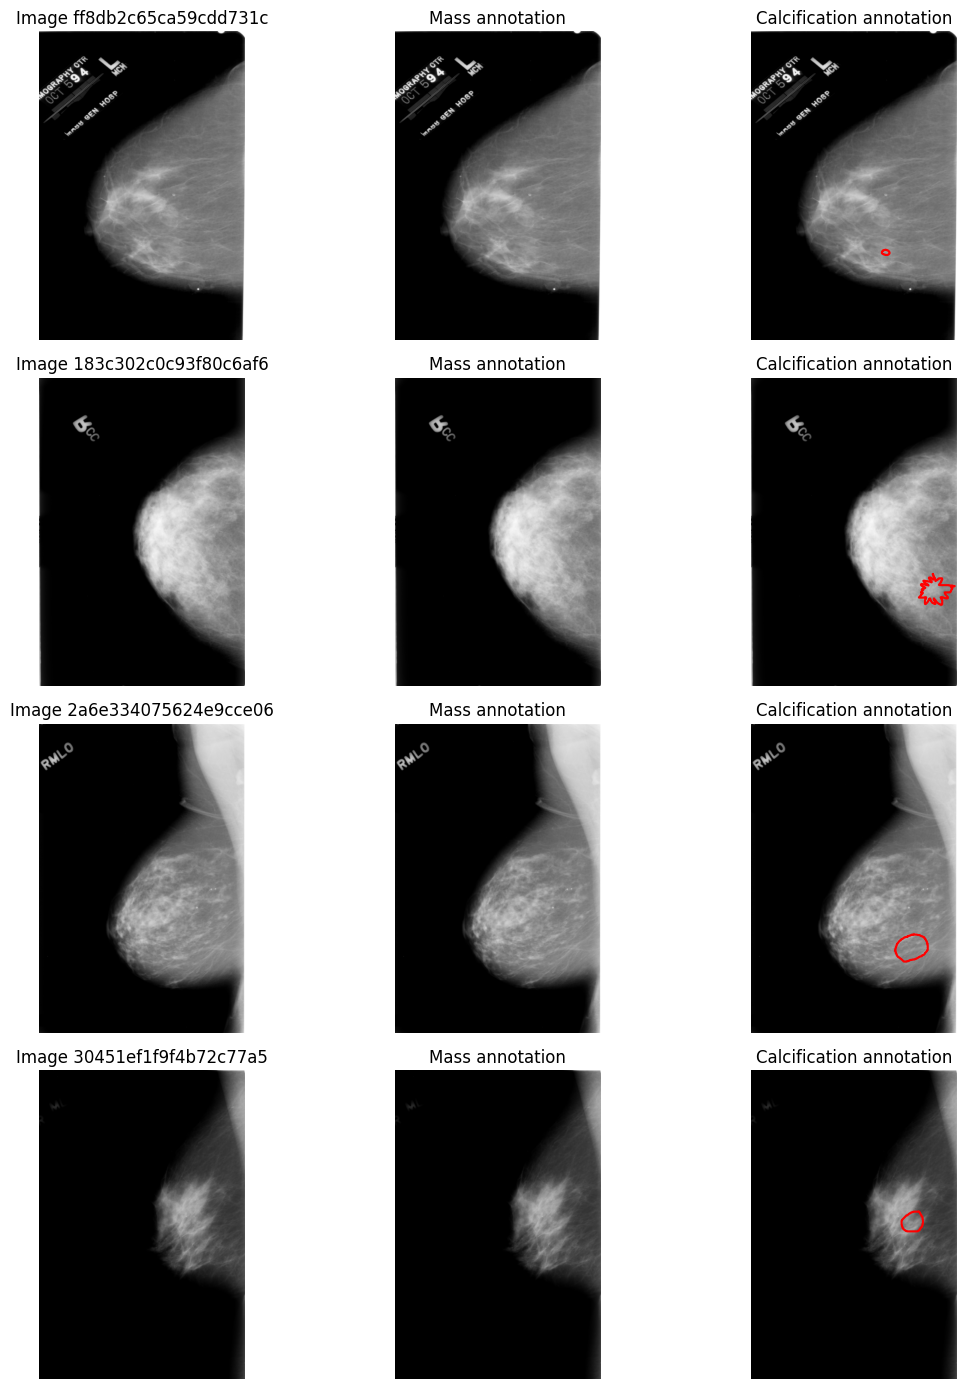

In [7]:
# 3b. Dataset, loaders and registration audit
class MammogramDataset(Dataset):
    def __init__(self,table,training=False): self.table=table.reset_index(drop=True); self.training=training
    def __len__(self): return len(self.table)
    def __getitem__(self,index):
        r=self.table.iloc[index]; x=np.asarray(Image.open(r.image_path),dtype=np.float32)/255
        with np.load(r.annotation_path) as z: target=z['target'].astype(np.float32); instances=z['instances'].astype(np.int64)
        if self.training:
            if random.random()<.5: x=x[:,::-1].copy(); target=target[:,:,::-1].copy(); instances=instances[:,::-1].copy()
            x=np.clip(x*random.uniform(.95,1.05),0,1)
        return dict(x=torch.from_numpy(x.copy())[None],target=torch.from_numpy(target.copy()),instances=torch.from_numpy(instances.copy()),
                    label=torch.tensor(float(r.label),dtype=torch.float32),patient=str(r.patient_id),image=str(r.image_id))

def worker_seed(worker_id):
    s=torch.initial_seed()%2**32; random.seed(s); np.random.seed(s)
loaders={s:DataLoader(MammogramDataset(prepared[prepared.split==s],s=='train'),batch_size=cfg.batch_size,shuffle=s=='train',
    num_workers=cfg.workers,worker_init_fn=worker_seed,generator=torch.Generator().manual_seed(cfg.seed),pin_memory=DEVICE.type=='cuda') for s in ['train','val','test']}

fig,axes=plt.subplots(min(4,len(loaders['val'].dataset)),3,figsize=(12,14),squeeze=False)
for i in range(len(axes)):
    sample=loaders['val'].dataset[i]
    for j in range(3): axes[i,j].imshow(sample['x'][0],cmap='gray'); axes[i,j].axis('off')
    axes[i,0].set_title('Image '+sample['image'])
    for t in range(2):
        if sample['target'][t].any(): axes[i,t+1].contour(sample['target'][t],levels=[.5],colors='red')
        axes[i,t+1].set_title(['Mass annotation','Calcification annotation'][t])
plt.tight_layout(); fig.savefig(RUN/'registration_audit.png',dpi=140); plt.show()
# Inspect the overlays. Stop execution if masks/intensity are incorrect.

## 4. Localization model and the two objectives
**LesionFields** (unchanged): image + local high-pass image -> full-resolution detail stream -> half-scale adaptive dilation branches (1/2/4) + quarter-scale context -> full-resolution fusion -> two sigmoid lesion maps (mass, calcification). No received-region input exists.

Section 5 defines the architecture and the CLEAN_V2 objective (model A). Section 6 adds the size-balanced multiscale squared error (model B). Both losses share the call signature `loss(out, batch, epoch) -> (loss, parts)` so that the same training function trains both.

In [8]:
# 5. LesionFields architecture + CLEAN_V2 localization loss
def conv(cin, cout, stride=1, dilation=1):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, stride, padding=dilation, dilation=dilation, bias=False),
        nn.GroupNorm(4, cout),
        nn.GELU()
    )

class LesionFields(nn.Module):
    """Same custom localization architecture as the supplied imaging-only notebook."""
    def __init__(self):
        super().__init__()
        self.detail = conv(2, 16)
        self.down = conv(16, 24, stride=2)
        self.context = nn.Sequential(conv(24, 32, stride=2), conv(32, 32, dilation=2))
        self.project = nn.Conv2d(32, 24, 1)
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(24, 24, 3, padding=d, dilation=d, groups=24),
                nn.Conv2d(24, 24, 1),
                nn.GELU()
            ) for d in [1, 2, 4]
        ])
        self.gate = nn.Conv2d(24, 3, 1)
        self.head = nn.Sequential(conv(40, 24), nn.Conv2d(24, 2, 1))

    def forward(self, x):
        # x is one-channel mammogram; concatenate high-pass channel internally.
        detail_input = torch.cat([x, x - F.avg_pool2d(x, 5, 1, 2)], 1)
        full = self.detail(detail_input)
        half = self.down(full)
        weights = self.gate(half).softmax(1)
        mixed = sum(weights[:, i:i+1] * branch(half) for i, branch in enumerate(self.branches))
        mixed = mixed + F.interpolate(
            self.project(self.context(half)), size=half.shape[-2:],
            mode="bilinear", align_corners=False
        )
        logits = self.head(torch.cat([
            full,
            F.interpolate(mixed, size=x.shape[-2:], mode="bilinear", align_corners=False)
        ], 1))
        p = logits.sigmoid()
        union = 1 - (1 - p).prod(1, keepdim=True)
        return {"logits": logits, "p": p, "union": union}

# CLEAN_V2 settings reported in the verification recipe / formula notes.
LOC_SOFT_KERNEL = 15
LOC_POSITIVE_WEIGHT = 10.0
LOC_TVERSKY_FP = 0.3
LOC_TVERSKY_FN = 0.7
LOC_PEAK_RADIUS = 24
LOC_PEAK_MAX_WEIGHT = 0.3

def soft_lesion_target(target, kernel=LOC_SOFT_KERNEL):
    return F.avg_pool2d(
        target.float(), kernel, stride=1, padding=kernel // 2,
        count_include_pad=False
    ).clamp(0, 1)

def clean_v2_localization_loss(logits, target, epoch):
    """
    Multi-channel adaptation of the uploaded CLEAN_V2 objective.
    Each lesion channel (mass/calcification) gets soft BCE + Tversky + peak-centering.
    Peak is calculated only for image/channel pairs that contain that lesion type.
    """
    logits = logits.float()
    p = torch.sigmoid(logits).clamp(1e-6, 1 - 1e-6)
    ys = soft_lesion_target(target)

    bce = -(
        LOC_POSITIVE_WEIGHT * ys * torch.log(p)
        + (1 - ys) * torch.log(1 - p)
    ).mean()

    dims = (2, 3)
    tp = (p * ys).sum(dims)
    fp = (p * (1 - ys)).sum(dims)
    fn = ((1 - p) * ys).sum(dims)
    tversky = (1 - (tp + 1) / (
        tp + LOC_TVERSKY_FP * fp + LOC_TVERSKY_FN * fn + 1
    )).mean()

    B, C, H, W = logits.shape
    gy, gx = torch.meshgrid(
        torch.arange(H, device=logits.device),
        torch.arange(W, device=logits.device),
        indexing="ij"
    )
    peak_terms = []
    for b in range(B):
        for c in range(C):
            yy, xx = torch.where(target[b, c] > 0.5)
            if len(xx) == 0:
                continue
            cy, cx = yy.float().mean(), xx.float().mean()
            near = ((gy - cy) ** 2 + (gx - cx) ** 2) <= LOC_PEAK_RADIUS ** 2
            spatial_prob = torch.softmax(logits[b, c].flatten(), dim=0)
            mass = spatial_prob[near.flatten()].sum().clamp_min(1e-8)
            peak_terms.append(-torch.log(mass))
    peak = torch.stack(peak_terms).mean() if peak_terms else logits.sum() * 0.0

    # Epochs are zero-indexed, matching CLEAN_V2.
    peak_weight = 0.0 if epoch < 5 else (0.1 if epoch == 5 else (0.2 if epoch == 6 else LOC_PEAK_MAX_WEIGHT))
    total = bce + tversky + peak_weight * peak
    return total, {
        "bce": bce.detach(),
        "tversky": tversky.detach(),
        "peak": peak.detach(),
        "peak_weight": peak_weight,
        "total": total.detach()
    }

def localization_dice(prob, target, threshold=0.5):
    pred = prob >= threshold
    truth = target > 0.5
    inter = (pred & truth).sum((1, 2, 3)).float()
    denom = pred.sum((1, 2, 3)).float() + truth.sum((1, 2, 3)).float()
    return ((2 * inter + 1e-7) / (denom + 1e-7)).mean().item()

In [9]:
# 4b. Experiment configuration (all new hyper-parameters in one place)
# ---- localization: identical recipe for both losses; only the loss differs
LOC_SEED = 42                     # model A (CLEAN_V2); model B uses LOC_SEED + 1
LOC_EPOCHS = 20
LOC_BATCH_SIZE = 4
LOC_LR = 3e-4
LOC_WEIGHT_DECAY = 1e-5
LOC_ENCODER_LR_MULT = 0.3
LOC_PATIENCE = 8
HIT_DILATION_RADIUS = 24          # pixels: hit = peak inside the 24-px dilated lesion mask (same as the earlier notebooks)
HIT_SIGMAS = (0, 3, 5, 8, 12, 16) # peak-smoothing grid; 0 = raw arg-max (hit@1), others chosen on validation
DICE_THRESHOLDS = tuple(float(t) for t in np.round(np.arange(.1, .91, .1), 2))
LOC_B_INIT_FROM_A = False         # False: B trained from scratch; True: B continues from A's best weights
ENSEMBLE_WEIGHTS = (0.5, 0.5)     # weights of (A, B) in the localization ensemble
LOC_GRID = (24, 16)               # token grid of the classifier (768/32 x 512/32)
# ---- classification
CLS_SEED = 52
CLS_EPOCHS = 20
CLS_PATIENCE = 5
CLS_LR = 3e-4
CLS_WEIGHT_DECAY = 1e-4
CLS_PHENO_PAIR_BATCH = 8          # collision pairs per step -> 16 whole mammograms per step
CLS_PHENO_PAIRS_PER_EPOCH = 2000  # random subset of the training pairs per epoch (None = all pairs)
CLS_BRIER_BATCH_SIZE = 2          # as in the specification; class balancing is therefore only within each tiny batch
LAMBDA_ATTR, LAMBDA_PAIR, LAMBDA_ORTH, DIAGNOSTIC_MARGIN = 0.5, 0.1, 0.1, 1.0
THRESHOLD_GRID = np.round(np.arange(.01, .995, .01), 2)   # 0.01 ... 0.99
ECE_BINS = 10
BOOTSTRAP_RESAMPLES = 1000


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


def to_device(batch):
    return {k: (v.to(DEVICE) if torch.is_tensor(v) else v) for k, v in batch.items()}


def wilson_interval(k, n, z=1.96):
    if n == 0: return float('nan'), float('nan')
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


json.dump(dict(LOC_SEED=LOC_SEED, LOC_EPOCHS=LOC_EPOCHS, LOC_BATCH_SIZE=LOC_BATCH_SIZE, LOC_LR=LOC_LR, HIT_SIGMAS=list(HIT_SIGMAS),
               LOC_B_INIT_FROM_A=LOC_B_INIT_FROM_A, ENSEMBLE_WEIGHTS=list(ENSEMBLE_WEIGHTS), CLS_SEED=CLS_SEED, CLS_EPOCHS=CLS_EPOCHS,
               CLS_LR=CLS_LR, CLS_BRIER_BATCH_SIZE=CLS_BRIER_BATCH_SIZE, CLS_PHENO_PAIR_BATCH=CLS_PHENO_PAIR_BATCH),
          open(RUN / 'experiment_config.json', 'w'), indent=2)

## 6. Model B objective: size-balanced multiscale squared error

In [10]:
# 6. Model B objective: size-balanced multiscale squared error
#    L_loc = ( ||W(p-y)||^2 + ||G1[W(p-y)]||^2 + ||G3[W(p-y)]||^2 ) / (K+1)   per image and lesion type,
#    averaged over images and the mass / calcification outputs.
_GAUSS_KERNELS = {}

def gaussian_kernel1d(sigma):
    radius = int(math.ceil(3 * sigma))
    x = torch.arange(-radius, radius + 1, dtype=torch.float32)
    k = torch.exp(-(x ** 2) / (2 * sigma ** 2))
    return k / k.sum()


def gaussian_blur(x, sigma):
    # Separable Gaussian smoothing of an (N,1,H,W) tensor with reflect padding; sigma <= 0 returns x unchanged.
    if sigma <= 0: return x
    key = (float(sigma), str(x.device), str(x.dtype))
    if key not in _GAUSS_KERNELS:
        _GAUSS_KERNELS[key] = gaussian_kernel1d(float(sigma)).to(device=x.device, dtype=x.dtype)
    k = _GAUSS_KERNELS[key]; r = (k.numel() - 1) // 2
    x = F.conv2d(F.pad(x, (r, r, 0, 0), mode='reflect'), k.view(1, 1, 1, -1))
    x = F.conv2d(F.pad(x, (0, 0, r, r), mode='reflect'), k.view(1, 1, -1, 1))
    return x


def instance_balance_weights(foreground, instances):
    # W for one image and one lesion type. foreground: (H,W) bool mask of this type; instances: (H,W) instance ids (0 = none).
    # Each lesion pixel gets 1/sqrt(area of ITS lesion), each background pixel 1/sqrt(background area). Returns (W, K).
    background_area = (~foreground).sum().clamp_min(1).float()
    W = torch.rsqrt(background_area) * torch.ones(foreground.shape, dtype=torch.float32, device=foreground.device)
    if not foreground.any(): return W, 0
    if cfg.balance_instances:
        ids, inverse, counts = torch.unique(instances[foreground], return_inverse=True, return_counts=True)
        W[foreground] = torch.rsqrt(counts.float())[inverse]
        return W, int(ids.numel())
    W[foreground] = torch.rsqrt(foreground.sum().float())          # one region per type (no size balancing)
    return W, 1


def balanced_multiscale_localization_loss(p, target, instances, scales=None):
    # p: (B,C,H,W) probabilities; target: (B,C,H,W) binary type masks; instances: (B,H,W) instance ids.
    scales = tuple(cfg.localization_scales if scales is None else scales)
    p = p.float(); B, C = p.shape[:2]
    per_item, per_scale = [], {s: [] for s in scales}
    for b in range(B):
        for c in range(C):
            foreground = target[b, c] > 0.5
            W, K = instance_balance_weights(foreground, instances[b])
            residual = (W * (p[b, c] - foreground.float()))[None, None]          # W(p - y)
            terms = [gaussian_blur(residual, float(s)).pow(2).sum() / (K + 1) for s in scales]
            for s, t in zip(scales, terms): per_scale[s].append(t.detach())
            per_item.append(sum(terms))
    loss = torch.stack(per_item).mean()
    parts = {'total': loss.detach(), **{f'scale{s}': torch.stack(v).mean() for s, v in per_scale.items()}}
    return loss, parts


def loss_clean_v2(out, batch, epoch):                  # model A
    return clean_v2_localization_loss(out['logits'], batch['target'], epoch)


def loss_balanced_msq(out, batch, epoch):              # model B (epoch is unused: no schedule)
    return balanced_multiscale_localization_loss(out['p'], batch['target'], batch['instances'])


LOC_LOSSES = {'clean_v2': loss_clean_v2, 'balanced_msq': loss_balanced_msq}
print('Registered localization losses:', list(LOC_LOSSES), '| smoothing scales:', cfg.localization_scales, '| balance_instances:', cfg.balance_instances)

Registered localization losses: ['clean_v2', 'balanced_msq'] | smoothing scales: (0, 1, 3) | balance_instances: True


## 7. Hit-rate and Dice utilities (as in the earlier localizer notebooks)

In [11]:
# 7. Hit-rate / Dice utilities (same definitions as the earlier localizer notebooks)
#    hit  = global peak of the union lesion map lies inside the lesion mask dilated by a 24-px disk
#    hit@1 = sigma 0 (raw arg-max, uploaded notebook); smoothed hit rate = peak of the Gaussian-smoothed map (earlier notebook)
_DILATED = {}

def dilated_mask(image_id, truth_mask, radius=HIT_DILATION_RADIUS):
    key = (str(image_id), radius)
    if key not in _DILATED:       # Euclidean distance <= radius is exactly dilation by a disk of that radius
        _DILATED[key] = ndimage.distance_transform_edt(~np.asarray(truth_mask, dtype=bool)) <= radius
    return _DILATED[key]


def hit_from_union(union, truth_masks, image_ids, sigma=0.0):
    # union: (B,1,H,W) tensor; truth_masks: list of (H,W) bool arrays. Returns a list of 0/1 hits.
    u = gaussian_blur(union, float(sigma)) if sigma > 0 else union
    flat = u.flatten(1).argmax(1).cpu().numpy(); width = u.shape[-1]
    return [float(dilated_mask(i, t)[ix // width, ix % width]) for i, t, ix in zip(image_ids, truth_masks, flat)]


def dice_per_image(prob, truth, threshold=0.5):
    pred = prob >= threshold; t = truth > 0.5
    inter = (pred & t).sum((1, 2, 3)).float(); denom = pred.sum((1, 2, 3)).float() + t.sum((1, 2, 3)).float()
    return ((2 * inter + 1e-7) / (denom + 1e-7)).cpu().tolist()


@torch.no_grad()
def evaluate_localizer_quick(model, loader, loss_name, epoch):
    # Per-epoch validation used for checkpoint selection: loss, Dice@0.5 and hit@1 (raw arg-max).
    model.eval(); loss_fn = LOC_LOSSES[loss_name]; losses, dices, hits = [], [], []
    for batch in loader:
        b = to_device(batch); out = model(b['x'])
        loss, _ = loss_fn(out, b, epoch); losses.append(float(loss.item()))
        truth = b['target'].sum(1, keepdim=True).clamp_max(1)
        dices.extend(dice_per_image(out['union'], truth, 0.5))
        hits.extend(hit_from_union(out['union'], [t[0].cpu().numpy() > 0.5 for t in truth], batch['image'], 0.0))
    return {'loss': float(np.mean(losses)), 'dice': float(np.mean(dices)), 'hit_at_1': float(np.mean(hits)), 'n_images': len(hits)}

## 8. Localizer training: model A (CLEAN_V2), then model B (balanced multiscale squared error)
The same function trains both. Checkpoint selection uses validation hit@1 with Dice as tie-breaker; a finished run is reloaded automatically when `cfg.resume` is True.

In [12]:
# 8. Train a LesionFields localizer with a chosen loss (used for model A and model B)
def make_loc_loaders(seed):
    return {s: DataLoader(MammogramDataset(prepared[prepared.split == s], training=(s == 'train')),
                          batch_size=LOC_BATCH_SIZE, shuffle=(s == 'train'), num_workers=cfg.workers, worker_init_fn=worker_seed,
                          generator=torch.Generator().manual_seed(seed), pin_memory=(DEVICE.type == 'cuda'))
            for s in ['train', 'val', 'test']}


def train_localizer(tag, loss_name, seed, init_state=None):
    best_path = RUN / f'lesionfields_{tag}_best.pt'; hist_path = RUN / f'localizer_{tag}_history.csv'
    seed_everything(seed)
    model = LesionFields().to(DEVICE)
    if cfg.resume and best_path.exists():
        state = torch.load(best_path, map_location=DEVICE, weights_only=False); model.load_state_dict(state['model_state_dict'])
        print(f'[{tag}] resumed finished run from {best_path.name}; best validation metrics:', state['val_metrics'])
        return model, (pd.read_csv(hist_path) if hist_path.exists() else pd.DataFrame())
    if init_state is not None: model.load_state_dict(init_state)
    loaders = make_loc_loaders(seed)
    encoder_params = [p for m in [model.detail, model.down, model.context, model.branches] for p in m.parameters()]
    decoder_params = [p for m in [model.project, model.gate, model.head] for p in m.parameters()]
    optimizer = torch.optim.AdamW([{'params': encoder_params, 'lr': LOC_LR * LOC_ENCODER_LR_MULT},
                                   {'params': decoder_params, 'lr': LOC_LR}], weight_decay=LOC_WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=LOC_EPOCHS)
    loss_fn = LOC_LOSSES[loss_name]; best_hit, best_dice, stale, history = -1.0, -1.0, 0, []
    for epoch in range(LOC_EPOCHS):
        model.train(); batch_losses = []
        for batch in loaders['train']:
            b = to_device(batch); optimizer.zero_grad(set_to_none=True)
            out = model(b['x']); loss, parts = loss_fn(out, b, epoch)
            if not torch.isfinite(loss): raise FloatingPointError(f'[{tag}] non-finite localization loss')
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); optimizer.step()
            batch_losses.append(float(loss.item()))
        val = evaluate_localizer_quick(model, loaders['val'], loss_name, epoch); scheduler.step()
        improved = (val['hit_at_1'] > best_hit) or (np.isclose(val['hit_at_1'], best_hit) and val['dice'] > best_dice)
        if improved:
            best_hit, best_dice, stale = val['hit_at_1'], val['dice'], 0
            torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch + 1, 'val_metrics': val, 'loss_name': loss_name,
                        'tag': tag, 'seed': seed}, best_path)
        else: stale += 1
        record = {'epoch': epoch + 1, 'train_loss': float(np.mean(batch_losses)), 'val_loss': val['loss'], 'val_dice': val['dice'],
                  'val_hit_at_1': val['hit_at_1'], 'selected': bool(improved)}
        history.append(record); print(f'[{tag}]', record); pd.DataFrame(history).to_csv(hist_path, index=False)
        if stale >= LOC_PATIENCE: print(f'[{tag}] early stopping'); break
    state = torch.load(best_path, map_location=DEVICE, weights_only=False); model.load_state_dict(state['model_state_dict'])
    print(f'[{tag}] best epoch {state["epoch"]}; validation metrics:', state['val_metrics'])
    return model, pd.DataFrame(history)

In [13]:
# 8a. MODEL A: LesionFields trained with the CLEAN_V2 loss
locA, histA = train_localizer('A_clean_v2', 'clean_v2', seed=LOC_SEED)

[A_clean_v2] resumed finished run from lesionfields_A_clean_v2_best.pt; best validation metrics: {'loss': 1.119456582599216, 'dice': 0.08890536352950006, 'hit_at_1': 0.17849462365591398, 'n_images': 465}


[B_balanced_msq] {'epoch': 1, 'train_loss': 0.35980370773455206, 'val_loss': 0.30357547715688366, 'val_dice': 0.06820798478529737, 'val_hit_at_1': 0.1978494623655914, 'selected': True}
[B_balanced_msq] {'epoch': 2, 'train_loss': 0.3058927532472062, 'val_loss': 0.2974850508647087, 'val_dice': 0.06709853339142398, 'val_hit_at_1': 0.20430107526881722, 'selected': True}
[B_balanced_msq] {'epoch': 3, 'train_loss': 0.29652118569512975, 'val_loss': 0.2758088607309211, 'val_dice': 0.06918916042331408, 'val_hit_at_1': 0.23225806451612904, 'selected': True}
[B_balanced_msq] {'epoch': 4, 'train_loss': 0.28812523940940954, 'val_loss': 0.282776531118613, 'val_dice': 0.0732367059214803, 'val_hit_at_1': 0.22795698924731184, 'selected': False}
[B_balanced_msq] {'epoch': 5, 'train_loss': 0.2818926173039403, 'val_loss': 0.2774282030315481, 'val_dice': 0.06667031707776257, 'val_hit_at_1': 0.26881720430107525, 'selected': True}
[B_balanced_msq] {'epoch': 6, 'train_loss': 0.27748772974691055, 'val_loss': 0

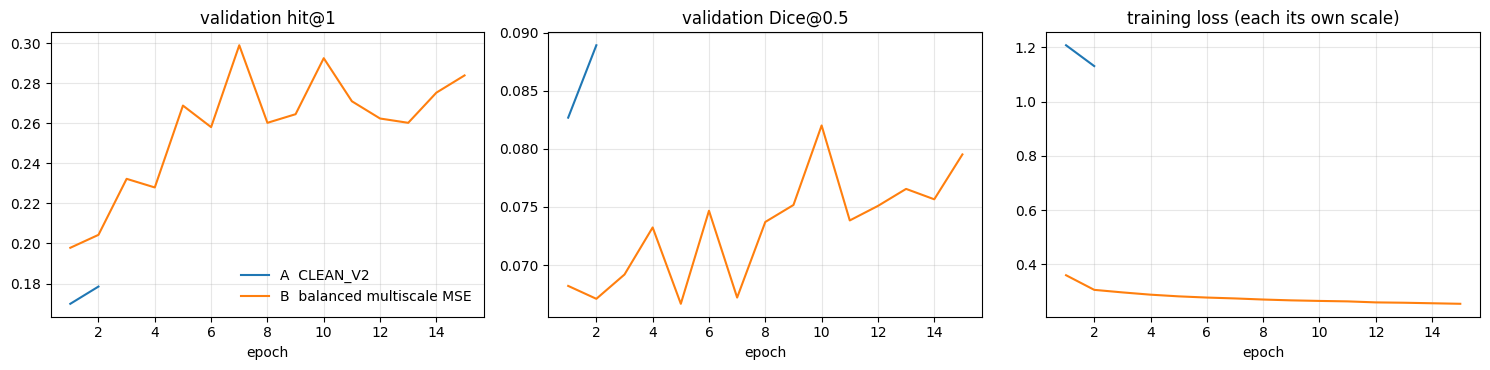

In [14]:
# 8b. MODEL B: LesionFields trained AGAIN, now with the size-balanced multiscale squared-error loss
init_B = {k: v.clone() for k, v in locA.state_dict().items()} if LOC_B_INIT_FROM_A else None
locB, histB = train_localizer('B_balanced_msq', 'balanced_msq', seed=LOC_SEED + 1, init_state=init_B)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for tag, h, color in [('A  CLEAN_V2', histA, 'tab:blue'), ('B  balanced multiscale MSE', histB, 'tab:orange')]:
    if len(h):
        axes[0].plot(h.epoch, h.val_hit_at_1, color=color, label=tag); axes[1].plot(h.epoch, h.val_dice, color=color)
        axes[2].plot(h.epoch, h.train_loss, color=color)
axes[0].set_title('validation hit@1'); axes[1].set_title('validation Dice@0.5'); axes[2].set_title('training loss (each its own scale)')
for a in axes: a.set_xlabel('epoch'); a.grid(alpha=.3)
axes[0].legend(frameon=False); plt.tight_layout(); fig.savefig(RUN / 'localizer_training_curves.png', dpi=140); plt.show()

## 9. Localization results: A, B and the ensemble
Sigma and the Dice threshold are chosen on validation; test is evaluated once at the end of this section.

In [15]:
# 9. Localization evaluation of A, B and the ensemble (ENS = weighted mean of the two probability maps)
@torch.no_grad()
def localization_sweep(models, loader, split, weights=ENSEMBLE_WEIGHTS, sigmas=HIT_SIGMAS, thresholds=DICE_THRESHOLDS):
    names = list(models)
    for m in models.values(): m.eval()
    rows = []
    for batch in loader:
        x = batch['x'].to(DEVICE)
        probs = {n: models[n](x)['p'].float() for n in names}
        probs['ENS'] = sum(w * probs[n] for w, n in zip(weights, names))
        truth_cpu = (batch['target'].sum(1, keepdim=True) > 0.5)                     # (B,1,H,W) bool on CPU
        truth_masks = [t[0].numpy() for t in truth_cpu]; truth_dev = truth_cpu.to(DEVICE).float()
        for variant, p in probs.items():
            union = 1 - (1 - p).prod(1, keepdim=True)
            rec = [dict(image_id=i, split=split, variant=variant) for i in batch['image']]
            for s in sigmas:
                for r, h in zip(rec, hit_from_union(union, truth_masks, batch['image'], s)): r[f'hit_s{s}'] = h
            for t in thresholds:
                for r, d in zip(rec, dice_per_image(union, truth_dev, t)): r[f'dice_t{t}'] = d
            rows.extend(rec)
    return pd.DataFrame(rows)


def summarize_localization(sweeps, sigmas=HIT_SIGMAS, thresholds=DICE_THRESHOLDS):
    # sigma and Dice threshold are chosen on VALIDATION for each variant and then applied unchanged to test.
    val = sweeps['val']; rows, chosen = [], {}
    for v in ['A', 'B', 'ENS']:
        dv = val[val.variant == v]
        s_star = max(sigmas, key=lambda s: (dv[f'hit_s{s}'].mean(), -s))
        t_star = max(thresholds, key=lambda t: dv[f'dice_t{t}'].mean())
        chosen[v] = (s_star, t_star)
        for split, df in sweeps.items():
            d = df[df.variant == v]; k = int(d[f'hit_s{s_star}'].sum()); n = len(d); lo, hi = wilson_interval(k, n)
            rows.append(dict(variant=v, split=split, n_images=n, hit_at_1_raw=d['hit_s0'].mean(), sigma_star=s_star,
                             hit_rate=d[f'hit_s{s_star}'].mean(), hit_ci_low=lo, hit_ci_high=hi,
                             dice_threshold=t_star, dice=d[f'dice_t{t_star}'].mean()))
    return pd.DataFrame(rows), chosen


EVAL_LOADERS = make_loc_loaders(LOC_SEED)
loc_sweeps = {'val': localization_sweep({'A': locA, 'B': locB}, EVAL_LOADERS['val'], 'val')}
loc_summary_val, loc_chosen = summarize_localization(loc_sweeps)
print('Validation (selection split) - sigma / Dice threshold chosen per variant:', loc_chosen)
display(loc_summary_val.round(4))

# complementarity of the two localizers at the raw arg-max (validation)
va = loc_sweeps['val']; pivot = va.pivot(index='image_id', columns='variant', values='hit_s0')
agreement = pd.crosstab(pivot['A'].map({1.0: 'A hit', 0.0: 'A miss'}), pivot['B'].map({1.0: 'B hit', 0.0: 'B miss'}))
print('Agreement of A and B (validation, hit@1):'); display(agreement)
print('Ensemble hit@1 on images where exactly one of A/B hit:', pivot.loc[pivot.A != pivot.B, 'ENS'].mean().round(3))

Validation (selection split) - sigma / Dice threshold chosen per variant: {'A': (12, 0.5), 'B': (8, 0.9), 'ENS': (8, 0.7)}


,variant,split,n_images,hit_at_1_raw,sigma_star,hit_rate,hit_ci_low,hit_ci_high,dice_threshold,dice
0,A,val,465,0.1785,12,0.2043,0.1701,0.2433,0.5,0.0889
1,B,val,465,0.2989,8,0.3462,0.3044,0.3906,0.9,0.1252
2,ENS,val,465,0.2645,8,0.3441,0.3023,0.3884,0.7,0.1261


Agreement of A and B (validation, hit@1):


B,B hit,B miss
A,,
A hit,54,29
A miss,85,297


Ensemble hit@1 on images where exactly one of A/B hit: 0.544


,variant,split,n_images,hit_at_1_raw,sigma_star,hit_rate,hit_ci_low,hit_ci_high,dice_threshold,dice
0,A,val,465,0.1785,12,0.2043,0.1701,0.2433,0.5,0.0889
1,A,test,482,0.1805,12,0.2012,0.1679,0.2393,0.5,0.1015
2,B,val,465,0.2989,8,0.3462,0.3044,0.3906,0.9,0.1252
3,B,test,482,0.2822,8,0.3382,0.2974,0.3815,0.9,0.1329
4,ENS,val,465,0.2645,8,0.3441,0.3023,0.3884,0.7,0.1261
5,ENS,test,482,0.2510,8,0.3174,0.2775,0.3603,0.7,0.1304


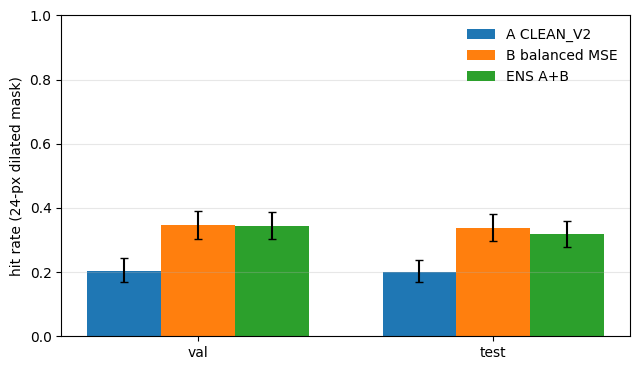

In [16]:
# 9b. Final localization numbers (test evaluated once, after sigma / threshold / ensemble choices are frozen on validation)
if RUN_TEST:
    loc_sweeps['test'] = localization_sweep({'A': locA, 'B': locB}, EVAL_LOADERS['test'], 'test')
loc_summary, loc_chosen = summarize_localization(loc_sweeps)      # chosen values still come from validation only
pd.concat(loc_sweeps.values()).to_csv(RUN / 'localization_per_image.csv', index=False)
loc_summary.to_csv(RUN / 'localization_summary.csv', index=False)
display(loc_summary.round(4))

fig, ax = plt.subplots(figsize=(6.5, 3.8)); width = .25
for i, (variant, color) in enumerate([('A', 'tab:blue'), ('B', 'tab:orange'), ('ENS', 'tab:green')]):
    sub = loc_summary[loc_summary.variant == variant]
    pos = np.arange(len(sub)) + (i - 1) * width
    ax.bar(pos, sub.hit_rate, width, color=color, label={'A': 'A CLEAN_V2', 'B': 'B balanced MSE', 'ENS': 'ENS A+B'}[variant],
           yerr=[sub.hit_rate - sub.hit_ci_low, sub.hit_ci_high - sub.hit_rate], capsize=3)
ax.set_xticks(np.arange(len(sub))); ax.set_xticklabels(sub.split); ax.set_ylabel('hit rate (24-px dilated mask)'); ax.set_ylim(0, 1)
ax.legend(frameon=False); ax.grid(axis='y', alpha=.3); plt.tight_layout(); fig.savefig(RUN / 'localization_hit_rates.png', dpi=140); plt.show()

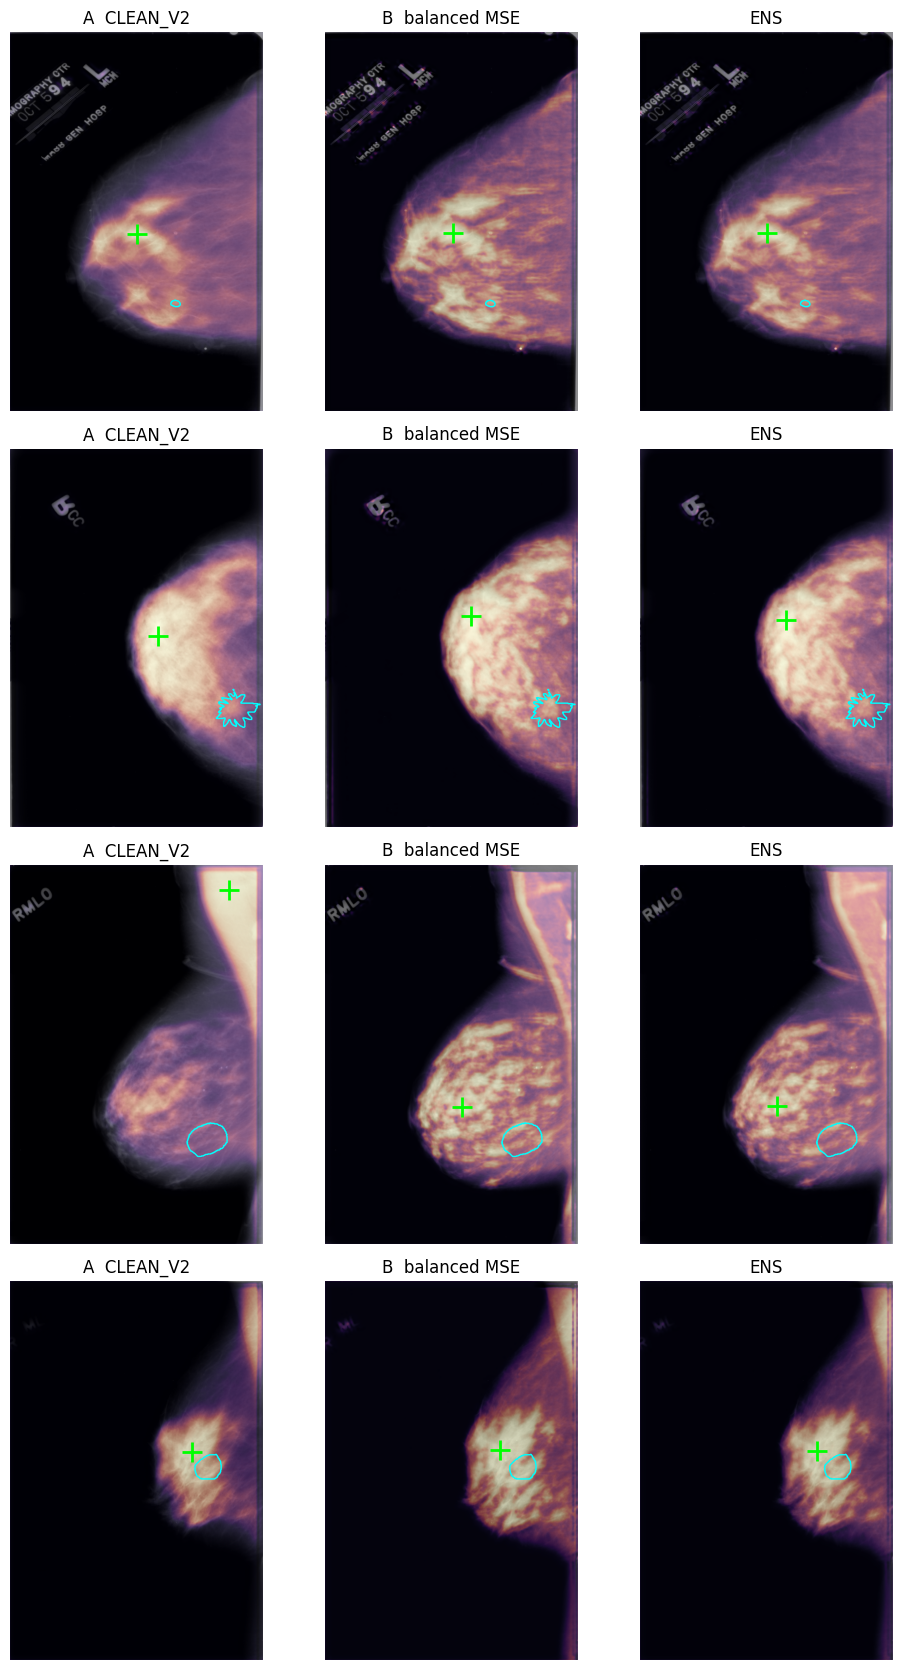

In [17]:
# 9c. Qualitative check: validation images with ground-truth contour and the peak chosen by A, B and the ensemble
@torch.no_grad()
def show_localization_examples(n=4):
    locA.eval(); locB.eval(); ds = EVAL_LOADERS['val'].dataset; n = min(n, len(ds))
    fig, axes = plt.subplots(n, 3, figsize=(10, 4.2 * n), squeeze=False)
    for r in range(n):
        s = ds[r]; x = s['x'][None].to(DEVICE)
        pa, pb = locA(x)['p'].float(), locB(x)['p'].float(); pe = ENSEMBLE_WEIGHTS[0] * pa + ENSEMBLE_WEIGHTS[1] * pb
        for c, (name, p) in enumerate([('A  CLEAN_V2', pa), ('B  balanced MSE', pb), ('ENS', pe)]):
            u = (1 - (1 - p).prod(1, keepdim=True)); sigma = loc_chosen['ENS' if name == 'ENS' else name[0]][0]
            us = gaussian_blur(u, float(sigma)) if sigma > 0 else u
            flat = int(us.flatten().argmax().item()); py, px = flat // us.shape[-1], flat % us.shape[-1]
            ax = axes[r, c]; ax.imshow(s['x'][0], cmap='gray'); ax.imshow(u[0, 0].cpu(), cmap='magma', alpha=.45)
            if s['target'].sum() > 0: ax.contour(s['target'].sum(0) > 0, levels=[.5], colors='cyan', linewidths=1)
            ax.plot(px, py, marker='+', color='lime', markersize=14, mew=2); ax.set_title(name); ax.axis('off')
    plt.tight_layout(); fig.savefig(RUN / 'localization_examples.png', dpi=130); plt.show()

show_localization_examples()

## 10. Phenotype descriptors, image-level frame and collision pairs
The descriptor recovery below is the uploaded notebook's (real CBIS-DDSM fields only, no invented labels). The classifier is **image level**: images with missing or mixed diagnoses are excluded. For an image, a descriptor is used only if all of its lesions agree on a single recorded value; the image's lesion type is used for pair matching only when all of its lesions have the same type. Training-only collision pairs: same lesion type, opposite pathology, different patients, at least one shared recorded descriptor.

In [18]:
# 6. Recover lesion phenotype descriptors and build lesion-centred datasets
# We deliberately use only actual CBIS-DDSM phenotype fields. Assessment/subtlety are not used.
DESC_CANDIDATES = ["mass_shape", "mass_margins", "calc_type", "calc_distribution"]

def norm_col(c):
    return str(c).strip().lower().replace(" ", "_").replace("-", "_")

def unique_nonmissing(s):
    vals = [str(v).strip() for v in s if pd.notna(v) and str(v).strip().lower() not in {"", "nan", "none"}]
    vals = list(dict.fromkeys(vals))
    return vals[0] if len(vals) == 1 else np.nan

# First use phenotype fields already present in the resolved manifest.
desc_present = [c for c in DESC_CANDIDATES if c in raw.columns and raw[c].notna().any()]
if not desc_present:
    csv_frames = []
    for csv_path in Path(cfg.data_dir).rglob("*.csv"):
        try:
            q = pd.read_csv(csv_path)
            q.columns = [norm_col(c) for c in q.columns]
        except Exception:
            continue
        available = [c for c in DESC_CANDIDATES if c in q.columns]
        keys = {"patient_id", "abnormality_id"}
        if not available or not keys.issubset(q.columns):
            continue
        q["patient_id"] = q["patient_id"].astype(str).str.strip()
        q["abnormality_id"] = q["abnormality_id"].astype(str).str.strip()
        if "abnormality_type" in q.columns:
            q["type_text"] = q["abnormality_type"].astype(str).str.lower()
        elif "lesion_type" in q.columns:
            q["type_text"] = q["lesion_type"].astype(str).str.lower()
        else:
            fname = str(csv_path).lower()
            inferred = "calc" if "calc" in fname else ("mass" if "mass" in fname else "")
            q["type_text"] = inferred
        q["type_code"] = np.where(q.type_text.str.contains("calc"), 2,
                                  np.where(q.type_text.str.contains("mass"), 1, 0))
        q = q[q.type_code > 0]
        keep = ["patient_id", "abnormality_id", "type_code"] + available
        csv_frames.append(q[keep])
    if not csv_frames:
        raise ValueError(
            "No mass_shape/mass_margins/calc_type/calc_distribution descriptors were found. "
            "Place the CBIS-DDSM case-description CSVs under cfg.data_dir or add these columns to the manifest. "
            "The notebook will not invent phenotype labels."
        )
    desc_raw = pd.concat(csv_frames, ignore_index=True)
    desc_agg = desc_raw.groupby(
        ["patient_id", "abnormality_id", "type_code"], dropna=False
    ).agg({c: unique_nonmissing for c in DESC_CANDIDATES if c in desc_raw.columns}).reset_index()
    raw = raw.merge(
        desc_agg, on=["patient_id", "abnormality_id", "type_code"],
        how="left", suffixes=("", "_csv")
    )
    for c in DESC_CANDIDATES:
        if c + "_csv" in raw.columns:
            if c not in raw.columns:
                raw[c] = raw[c + "_csv"]
            else:
                raw[c] = raw[c].where(raw[c].notna(), raw[c + "_csv"])
            raw.drop(columns=[c + "_csv"], inplace=True)

desc_cols = [c for c in DESC_CANDIDATES if c in raw.columns and raw[c].notna().any()]
if not desc_cols:
    raise ValueError("No usable phenotype descriptor columns after metadata join.")

# Link abnormality-level records to the resized registered instance masks.
split_by_full = prepared.set_index("full_file")["split"].to_dict()
prepared_by_full = prepared.set_index("full_file").to_dict("index")
lesion_rows = []
raw_lesions = raw.drop_duplicates(
    ["patient_id", "full_file_resolved", "abnormality_id", "type_code", "diagnosis"]
)
for r in raw_lesions.itertuples():
    full = r.full_file_resolved
    if full not in prepared_by_full or not np.isfinite(r.diagnosis):
        continue
    pr = prepared_by_full[full]
    meta = json.load(open(pr["metadata_path"]))
    match = [
        z for z in meta["lesions"]
        if str(z["abnormality_id"]) == str(r.abnormality_id)
        and int(z["type_code"]) == int(r.type_code)
    ]
    if len(match) != 1:
        continue
    lesion = match[0]
    row = {
        "patient_id": str(r.patient_id),
        "image_id": str(pr["image_id"]),
        "split": str(pr["split"]),
        "label": int(r.diagnosis),
        "lesion_type": str(r.lesion_type).lower(),
        "type_code": int(r.type_code),
        "abnormality_id": str(r.abnormality_id),
        "image_path": pr["image_path"],
        "annotation_path": pr["annotation_path"],
        "instance_id": int(lesion["instance"])
    }
    for c in desc_cols:
        value = getattr(r, c, np.nan)
        row[c] = str(value).strip() if pd.notna(value) and str(value).strip() else np.nan
    lesion_rows.append(row)

lesion_frame = pd.DataFrame(lesion_rows).drop_duplicates(
    ["patient_id", "image_id", "abnormality_id", "type_code"]
).reset_index(drop=True)
if lesion_frame.empty:
    raise ValueError("No lesion-level records could be linked to registered annotation instances.")
print("Lesion records by split:")
display(lesion_frame.groupby("split").agg(lesions=("label", "size"), patients=("patient_id", "nunique")))
print("Candidate descriptors:", desc_cols)

# Keep descriptors with at least two categories in training.
train_mask = lesion_frame.split.eq("train")
desc_cols = [
    c for c in desc_cols
    if lesion_frame.loc[train_mask, c].dropna().astype(str).nunique() >= 2
]
if not desc_cols:
    raise ValueError("No descriptor has at least two observed training categories; phenotype objective cannot be trained.")

for c in desc_cols:
    lesion_frame[c] = lesion_frame[c].map(
        lambda v: str(v).strip() if pd.notna(v) and str(v).strip() else np.nan
    )

descriptor_vocab = {
    c: {v: i for i, v in enumerate(sorted(lesion_frame.loc[train_mask, c].dropna().unique()))}
    for c in desc_cols
}
attribute_sizes = [len(descriptor_vocab[c]) for c in desc_cols]

def encode_descriptors(frame):
    out = np.full((len(frame), len(desc_cols)), -1, dtype=np.int64)
    for j, c in enumerate(desc_cols):
        vocab = descriptor_vocab[c]
        out[:, j] = [vocab.get(str(v), -1) if pd.notna(v) else -1 for v in frame[c]]
    return out

lesion_frame["row_idx"] = np.arange(len(lesion_frame))
desc_codes_all = encode_descriptors(lesion_frame)

Lesion records by split:


,lesions,patients
split,,
test,589,235
train,2448,1096
val,530,235


Candidate descriptors: ['mass_shape', 'mass_margins', 'calc_type', 'calc_distribution']


In [19]:
# 10b. Image-level classification frame, descriptor codes and training-only phenotype-collision pairs
cls_all = prepared[prepared.label.notna() & (~prepared.mixed.astype(bool))].copy()
lesions_by_image = {k: v for k, v in lesion_frame.groupby('image_id')}
frame_rows = []
for r in cls_all.itertuples():
    g = lesions_by_image.get(str(r.image_id)); types = set(g.type_code) if g is not None else set()
    row = dict(image_id=str(r.image_id), patient_id=str(r.patient_id), split=str(r.split), label=int(r.label),
               image_path=r.image_path, n_lesions=0 if g is None else len(g), type_code=next(iter(types)) if len(types) == 1 else 0)
    for c in desc_cols:
        vals = [] if g is None else list(dict.fromkeys(v for v in g[c].dropna().astype(str) if v.strip()))
        row[c] = vals[0] if len(vals) == 1 else np.nan
    frame_rows.append(row)
cls_frame = pd.DataFrame(frame_rows).reset_index(drop=True)
print('Image-level classification frame (missing / mixed diagnoses excluded):'); display(cls_frame.groupby('split').agg(
    images=('image_id', 'size'), patients=('patient_id', 'nunique'), malignant=('label', 'sum'), single_type=('type_code', lambda s: int((s > 0).sum()))))
for s in ['train', 'val', 'test']:
    if cls_frame[cls_frame.split == s].label.nunique() != 2: raise ValueError(f'{s} split needs both classes')

cls_train = cls_frame[cls_frame.split == 'train'].reset_index(drop=True)
cls_val = cls_frame[cls_frame.split == 'val'].reset_index(drop=True)
cls_test = cls_frame[cls_frame.split == 'test'].reset_index(drop=True)
cls_train_codes = encode_descriptors(cls_train)


def build_image_collision_pairs(frame, codes, top_k=3, tau=0.5):
    # pairs of images of the same single lesion type, opposite diagnosis, different patients, >=1 shared descriptor
    pairs = {}; labels = frame.label.astype(int).to_numpy(); types = frame.type_code.to_numpy(); patients = frame.patient_id.astype(str).to_numpy()
    for i in range(len(frame)):
        if types[i] == 0: continue
        cand = np.where((labels != labels[i]) & (types == types[i]) & (patients != patients[i]))[0]
        if len(cand) == 0: continue
        common = (codes[cand] >= 0) & (codes[i][None, :] >= 0); count = common.sum(1); ok = count > 0
        if not ok.any(): continue
        dist = ((codes[cand] != codes[i][None, :]) & common).sum(1) / np.maximum(count, 1)
        ok_idx = np.where(ok)[0]
        for q in ok_idx[np.argsort(dist[ok_idx])[:top_k]]:
            j = int(cand[q]); a, b = sorted((int(i), j)); w = float(np.exp(-float(dist[q]) / tau))
            if a != b and ((a, b) not in pairs or w > pairs[(a, b)]): pairs[(a, b)] = w
    return [(i, j, w) for (i, j), w in pairs.items()]


image_pairs = build_image_collision_pairs(cls_train, cls_train_codes)
if not image_pairs: raise ValueError('No image-level collision pairs; check descriptor coverage and benign/malignant overlap within lesion type.')
print('Descriptor fields:', desc_cols, '| attribute sizes:', attribute_sizes, '| training collision pairs:', len(image_pairs))
n_pos_img = int(cls_train.label.sum()); n_neg_img = int(len(cls_train) - n_pos_img)
POS_WEIGHT = torch.tensor([n_neg_img / max(n_pos_img, 1)], dtype=torch.float32, device=DEVICE)
print(f'Training images: {len(cls_train)} (malignant {n_pos_img}, benign {n_neg_img}); BCE positive weight {POS_WEIGHT.item():.3f}')

Image-level classification frame (missing / mixed diagnoses excluded):


,images,patients,malignant,single_type
split,,,,
test,478,234,174,478
train,2146,1094,973,2146
val,462,234,211,462


Descriptor fields: ['mass_shape', 'mass_margins', 'calc_type', 'calc_distribution'] | attribute sizes: [14, 14, 28, 8] | training collision pairs: 5847
Training images: 2146 (malignant 973, benign 1173); BCE positive weight 1.206


## 11. Localization statistics for the classifier
The three statistics per 32x32 cell come from the **ensemble** localizer; no ground-truth centre is used anywhere in the classifier.

In [20]:
# 11. Predicted-localization statistics for the classifier, from the localizer ENSEMBLE (no annotation is used here)
#     per 32x32 cell: mean mass probability, mean calcification probability, maximum lesion (union) probability
class ImageOnlyDataset(Dataset):
    def __init__(self, table): self.table = table.reset_index(drop=True)
    def __len__(self): return len(self.table)
    def __getitem__(self, i):
        r = self.table.iloc[i]; x = np.asarray(Image.open(r.image_path).convert('L'), dtype=np.float32) / 255
        return {'x': torch.from_numpy(x)[None], 'image': str(r.image_id)}


@torch.no_grad()
def compute_localization_stats(models, weights, table, grid=LOC_GRID):
    for m in models: m.eval()
    stats = {}
    for batch in DataLoader(ImageOnlyDataset(table), batch_size=4, shuffle=False, num_workers=cfg.workers):
        x = batch['x'].to(DEVICE); p = sum(w * m(x)['p'].float() for w, m in zip(weights, models))
        union = 1 - (1 - p).prod(1, keepdim=True)
        s = torch.cat([F.adaptive_avg_pool2d(p[:, 0:1], grid), F.adaptive_avg_pool2d(p[:, 1:2], grid), F.adaptive_max_pool2d(union, grid)], 1)
        for image_id, arr in zip(batch['image'], s.cpu().numpy().astype(np.float32)): stats[image_id] = arr
    return stats


stats_path = RUN / 'localization_stats_ensemble.npz'
if cfg.resume and stats_path.exists():
    z = np.load(stats_path, allow_pickle=False); LOC_STATS = dict(zip(z['ids'].tolist(), z['stats']))
    missing = set(cls_frame.image_id) - set(LOC_STATS)
    if missing: LOC_STATS.update(compute_localization_stats([locA, locB], ENSEMBLE_WEIGHTS, cls_frame[cls_frame.image_id.isin(missing)]))
else:
    LOC_STATS = compute_localization_stats([locA, locB], ENSEMBLE_WEIGHTS, cls_frame)
np.savez_compressed(stats_path, ids=np.array(list(LOC_STATS)), stats=np.stack(list(LOC_STATS.values())))
print('Localization statistics for', len(LOC_STATS), 'images; array shape', next(iter(LOC_STATS.values())).shape)
# NOTE: for TRAIN images the localizers have seen the masks, so their statistics are cleaner than on val/test (see section 19).

Localization statistics for 3086 images; array shape (3, 24, 16)


## 12. Image-level datasets

In [21]:
# 12. Image-level datasets (whole mammogram + localization statistics)
class ImageClassDataset(Dataset):
    def __init__(self, frame, stats, training=False):
        self.frame = frame.reset_index(drop=True); self.stats = stats; self.training = training; self.codes = encode_descriptors(self.frame)
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        r = self.frame.iloc[i]; x = np.asarray(Image.open(r.image_path).convert('L'), dtype=np.float32) / 255
        loc = self.stats[r.image_id].copy()
        if self.training:
            if random.random() < .5: x = x[:, ::-1]; loc = loc[:, :, ::-1]      # flip image and its token grid together
            x = np.clip(x * random.uniform(.95, 1.05), 0, 1)
        return {'x': torch.from_numpy(np.ascontiguousarray(x))[None], 'loc': torch.from_numpy(np.ascontiguousarray(loc)),
                'label': torch.tensor(float(r.label)), 'attrs': torch.from_numpy(self.codes[i]), 'patient': str(r.patient_id), 'image': str(r.image_id)}


class ImagePairDataset(Dataset):
    def __init__(self, base, pairs): self.base = base; self.pairs = pairs
    def __len__(self): return len(self.pairs)
    def __getitem__(self, k):
        i, j, w = self.pairs[k]; return self.base[i], self.base[j], torch.tensor(w, dtype=torch.float32)


train_ds = ImageClassDataset(cls_train, LOC_STATS, training=True)
val_loader_cls = DataLoader(ImageClassDataset(cls_val, LOC_STATS), batch_size=8, shuffle=False, num_workers=cfg.workers)
test_loader_cls = DataLoader(ImageClassDataset(cls_test, LOC_STATS), batch_size=8, shuffle=False, num_workers=cfg.workers)
pair_ds = ImagePairDataset(train_ds, image_pairs)

## 13. ImageTokenClassifier (supplied architecture)

In [22]:
# 13. ImageTokenClassifier (architecture of the supplied figure)
#   mammogram + high-pass (B x 2 x 768 x 512) -> Conv3x3 2->16 s2 -> 16->32 s2 -> 32->64 s2 (GN(4)+GELU) -> adaptive avg pool 24x16
#   + 3 predicted-localization statistics (mean mass, mean calcification, max lesion prob) -> 67 -> linear 64 + projected (y,x) coordinates
#   -> 384 image tokens + global token (mean) = 385 tokens
#   -> 4 learned latent queries, 4-head cross-attention (bounded localization bias) , query residual + LayerNorm -> B x 4 x 64
#   -> 1 learned diagnostic query, 4-head cross-attention over 385 + 4 = 389 tokens -> B x 1 x 64
#   -> concat(diagnostic output, global token) = 128 -> Linear 128->64 -> GELU -> Linear 64->1 -> sigmoid
class CrossAttention(nn.Module):
    def __init__(self, dim=64, heads=4):
        super().__init__(); assert dim % heads == 0
        self.h, self.dk = heads, dim // heads
        self.q, self.k, self.v, self.o = nn.Linear(dim, dim), nn.Linear(dim, dim), nn.Linear(dim, dim), nn.Linear(dim, dim)
    def forward(self, query, context, bias=None):
        B, Lq, _ = query.shape; Lk = context.shape[1]
        q = self.q(query).view(B, Lq, self.h, self.dk).transpose(1, 2)
        k = self.k(context).view(B, Lk, self.h, self.dk).transpose(1, 2)
        v = self.v(context).view(B, Lk, self.h, self.dk).transpose(1, 2)
        att = (q @ k.transpose(-1, -2)) / math.sqrt(self.dk)                   # B,h,Lq,Lk
        if bias is not None: att = att + bias[:, None, None, :]                  # additive key bias (B,Lk)
        att = att.softmax(-1)
        return self.o((att @ v).transpose(1, 2).reshape(B, Lq, -1))


class ImageTokenClassifier(nn.Module):
    def __init__(self, grid=LOC_GRID, n_loc=3, dim=64, n_latents=4, heads=4, attribute_sizes=(), max_bias=2.0):
        super().__init__()
        self.grid, self.dim, self.max_bias = grid, dim, max_bias
        self.stem = nn.Sequential(conv(2, 16, stride=2), conv(16, 32, stride=2), conv(32, 64, stride=2))
        self.pool = nn.AdaptiveAvgPool2d(grid)
        self.token_proj = nn.Linear(64 + n_loc, dim)                  # 67 -> 64
        self.coord_proj = nn.Linear(2, dim)
        self.latent_queries = nn.Parameter(torch.randn(n_latents, dim) * 0.02)
        self.diag_query = nn.Parameter(torch.randn(1, dim) * 0.02)
        self.latent_attn, self.latent_norm = CrossAttention(dim, heads), nn.LayerNorm(dim)
        self.diag_attn = CrossAttention(dim, heads)
        self.bias_gain = nn.Parameter(torch.tensor(3.0))             # learnable gain; the bias itself is bounded by max_bias via tanh
        self.head_hidden, self.head_out = nn.Linear(2 * dim, dim), nn.Linear(dim, 1)
        self.pheno_proj = nn.Linear(dim, dim)                         # phenotype embedding u (used by the phenotype objective only)
        self.attribute_heads = nn.ModuleList([nn.Linear(dim, int(s)) for s in attribute_sizes])
        ys, xs = torch.meshgrid(torch.linspace(-1, 1, grid[0]), torch.linspace(-1, 1, grid[1]), indexing='ij')
        self.register_buffer('coords', torch.stack([ys, xs], -1).view(-1, 2))

    def forward(self, x, loc):
        # x: (B,1,H,W) mammogram; loc: (B,3,24,16) = mean mass, mean calcification, max lesion probability per cell
        feat = self.pool(self.stem(torch.cat([x, x - F.avg_pool2d(x, 5, 1, 2)], 1)))          # B,64,24,16
        B = feat.shape[0]
        tokens = torch.cat([feat, loc], 1).flatten(2).transpose(1, 2)                          # B,384,67
        tokens = self.token_proj(tokens) + self.coord_proj(self.coords)[None]                  # B,384,64
        glob = tokens.mean(1, keepdim=True)                                                    # B,1,64
        kv = torch.cat([tokens, glob], 1)                                                      # B,385,64
        bias = self.max_bias * torch.tanh(self.bias_gain * loc[:, 2].flatten(1))               # B,384 bounded in [0,max_bias]
        bias = torch.cat([bias, bias.new_zeros(B, 1)], 1)                                      # global token: no bias
        lq = self.latent_queries[None].expand(B, -1, -1)
        lat = self.latent_norm(lq + self.latent_attn(lq, kv, bias))                            # B,4,64
        kv2 = torch.cat([kv, lat], 1); bias2 = torch.cat([bias, bias.new_zeros(B, lat.shape[1])], 1)   # B,389,64
        diag = self.diag_attn(self.diag_query[None].expand(B, -1, -1), kv2, bias2)[:, 0]       # B,64
        h = F.gelu(self.head_hidden(torch.cat([diag, glob[:, 0]], 1)))                         # B,64
        logit = self.head_out(h).squeeze(1)                                                    # B
        u = F.normalize(self.pheno_proj(lat.mean(1)), dim=1); v = F.normalize(h, dim=1)
        return {'logit': logit, 'u': u, 'v': v, 'attr_logits': [head(u) for head in self.attribute_heads]}


_probe = ImageTokenClassifier(attribute_sizes=attribute_sizes)
print('ImageTokenClassifier parameters:', sum(p.numel() for p in _probe.parameters()), '| trainable:', sum(p.numel() for p in _probe.parameters() if p.requires_grad))
del _probe

ImageTokenClassifier parameters: 78466 | trainable: 78466


## 14. Classification losses and metrics
1. **Phenotype objective** (first): weighted BCE + 0.5 attribute + 0.1 pair + 0.1 orthogonality.
2. **Class-balanced Brier loss**: $L_{cls}=\frac12\left[\frac1{N_0}\sum_{y_i=0}p_i^2+\frac1{N_1}\sum_{y_i=1}(p_i-1)^2\right]$; with one class in the batch the loss is averaged over that class.

Evaluation Brier score is the ordinary unweighted score. ROC-AUC selects checkpoints; the threshold maximises validation balanced accuracy over {0.01, ..., 0.99}.

In [23]:
# 14. Classification losses and metrics
def phenotype_objective(out, y, attrs, n, pair_weights, pos_weight=None):
    # weighted BCE + 0.5 attribute + 0.1 pair + 0.1 orthogonality. The first n samples and the last n samples are the two members of the pairs.
    pos_weight = POS_WEIGHT if pos_weight is None else pos_weight
    logits, u, v = out['logit'], out['u'], out['v']
    loss_cls = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight)
    terms = []
    for r, scores in enumerate(out['attr_logits']):
        target = attrs[:, r]; valid = target >= 0
        if valid.any(): terms.append(F.cross_entropy(scores[valid], target[valid]))
    loss_attr = torch.stack(terms).mean() if terms else logits.sum() * 0.0
    phenotype_distance = ((u[:n] - u[n:]) ** 2).sum(1)
    diagnostic_distance = torch.linalg.vector_norm(v[:n] - v[n:], ord=2, dim=1)
    pair_per_sample = phenotype_distance + F.relu(DIAGNOSTIC_MARGIN - diagnostic_distance) ** 2
    loss_pair = (pair_weights * pair_per_sample).sum() / pair_weights.sum().clamp_min(1e-8)
    uc, vc = u - u.mean(0, keepdim=True), v - v.mean(0, keepdim=True)
    loss_orth = (((uc.T @ vc) / max(u.shape[0], 1)) ** 2).sum()
    total = loss_cls + LAMBDA_ATTR * loss_attr + LAMBDA_PAIR * loss_pair + LAMBDA_ORTH * loss_orth
    return total, {'classification': loss_cls.detach(), 'attribute': loss_attr.detach(), 'pair': loss_pair.detach(),
                   'orthogonality': loss_orth.detach(), 'total': total.detach()}


def class_balanced_brier_loss(logit, y):
    # L = 1/2 [ mean_{y=0} p^2 + mean_{y=1} (p-1)^2 ]; with one class in the batch, the mean over that class only.
    p = torch.sigmoid(logit); y = y.float(); neg, pos = y < 0.5, y >= 0.5; terms = []
    if neg.any(): terms.append((p[neg] ** 2).mean())
    if pos.any(): terms.append(((p[pos] - 1) ** 2).mean())
    return sum(terms) / len(terms)


def safe_auc(y, p):
    return float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else float('nan')


def expected_calibration_error(y, p, bins=ECE_BINS):
    y, p = np.asarray(y, float), np.asarray(p, float); edges = np.linspace(0, 1, bins + 1); ece = 0.0
    for i in range(bins):
        m = (p >= edges[i]) & ((p < edges[i + 1]) if i < bins - 1 else (p <= edges[i + 1]))
        if m.any(): ece += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(ece)


def choose_threshold_balanced_accuracy(y, p, grid=THRESHOLD_GRID):
    # t* = argmax over {0.01,...,0.99} of validation balanced accuracy (ties -> lowest threshold)
    scores = [balanced_accuracy_score(y, (p >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(scores))]), float(np.max(scores))


def classification_metrics(y, p, threshold):
    y = np.asarray(y).astype(int); p = np.asarray(p, float); pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    return {'n': int(len(y)), 'threshold': float(threshold), 'roc_auc': safe_auc(y, p),
            'average_precision': float(average_precision_score(y, p)) if y.sum() else float('nan'),   # AP (not trapezoidal PR-AUC)
            'sensitivity': float(sens), 'specificity': float(spec), 'f1': float(2 * tp / max(2 * tp + fp + fn, 1)),
            'balanced_accuracy': float((sens + spec) / 2), 'brier': float(np.mean((p - y) ** 2)),
            'ece': expected_calibration_error(y, p), 'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}


def patient_bootstrap_auc(df, resamples=BOOTSTRAP_RESAMPLES, seed=0):
    df = df.reset_index(drop=True); rng = np.random.default_rng(seed); groups = [g.index.values for _, g in df.groupby('patient_id')]; vals = []
    for _ in range(resamples):
        sel = np.concatenate([groups[k] for k in rng.integers(0, len(groups), len(groups))]); yy = df.label.values[sel]
        if len(np.unique(yy)) == 2: vals.append(roc_auc_score(yy, df.prob.values[sel]))
    return tuple(np.percentile(vals, [2.5, 97.5])) if vals else (float('nan'), float('nan'))


@torch.no_grad()
def predict_classifier(model, loader):
    model.eval(); rows = []
    for b in loader:
        p = torch.sigmoid(model(b['x'].to(DEVICE), b['loc'].to(DEVICE))['logit']).cpu().numpy()
        rows += list(zip(b['image'], b['patient'], b['label'].numpy().astype(int).tolist(), p.tolist()))
    return pd.DataFrame(rows, columns=['image_id', 'patient_id', 'label', 'prob'])

## 15. Classifier training: pheno objective first, then class-balanced Brier

In [24]:
# 15. Train the ImageTokenClassifier with a chosen loss (mode 'pheno' or 'brier')
def train_classifier(tag, mode, seed):
    best_path = RUN / f'image_token_classifier_{tag}_best.pt'; hist_path = RUN / f'classifier_{tag}_history.csv'
    seed_everything(seed)
    model = ImageTokenClassifier(attribute_sizes=attribute_sizes if mode == 'pheno' else ()).to(DEVICE)
    if cfg.resume and best_path.exists():
        state = torch.load(best_path, map_location=DEVICE, weights_only=False); model.load_state_dict(state['model_state_dict'])
        print(f'[{tag}] resumed finished run; best validation ROC-AUC {state["best_val_auc"]:.4f}')
        return model, (pd.read_csv(hist_path) if hist_path.exists() else pd.DataFrame())
    pair_rng = np.random.default_rng(seed)
    n_pairs = len(pair_ds) if CLS_PHENO_PAIRS_PER_EPOCH is None else min(len(pair_ds), CLS_PHENO_PAIRS_PER_EPOCH)
    brier_loader = DataLoader(train_ds, batch_size=CLS_BRIER_BATCH_SIZE, shuffle=True, num_workers=cfg.workers, pin_memory=(DEVICE.type == 'cuda'),
                              generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=CLS_LR, weight_decay=CLS_WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CLS_EPOCHS)
    best_auc, stale, history = -1.0, 0, []
    for epoch in range(CLS_EPOCHS):
        model.train(); running, seen = {}, 0
        if mode == 'pheno':      # a fresh random subset of the collision pairs every epoch
            subset = torch.utils.data.Subset(pair_ds, pair_rng.permutation(len(pair_ds))[:n_pairs].tolist())
            loader = DataLoader(subset, batch_size=CLS_PHENO_PAIR_BATCH, shuffle=True, num_workers=cfg.workers, pin_memory=(DEVICE.type == 'cuda'))
        else: loader = brier_loader
        for batch in loader:
            if mode == 'pheno':
                a, b, pw = batch; x = torch.cat([a['x'], b['x']]).to(DEVICE); loc = torch.cat([a['loc'], b['loc']]).to(DEVICE)
                y = torch.cat([a['label'], b['label']]).to(DEVICE); attrs = torch.cat([a['attrs'], b['attrs']]).to(DEVICE)
                out = model(x, loc); loss, parts = phenotype_objective(out, y, attrs, len(a['x']), pw.to(DEVICE))
            else:
                x, loc, y = batch['x'].to(DEVICE), batch['loc'].to(DEVICE), batch['label'].to(DEVICE)
                out = model(x, loc); loss = class_balanced_brier_loss(out['logit'], y); parts = {'total': loss.detach()}
            if not torch.isfinite(loss): raise FloatingPointError(f'[{tag}] non-finite loss')
            optimizer.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); optimizer.step()
            for k, v in parts.items(): running[k] = running.get(k, 0.0) + float(v) * len(y)
            seen += len(y)
        scheduler.step()
        val_pred = predict_classifier(model, val_loader_cls); val_auc = safe_auc(val_pred.label.values, val_pred.prob.values)
        record = {'epoch': epoch + 1, **{f'train_{k}': v / max(seen, 1) for k, v in running.items()}, 'val_auc': val_auc}
        history.append(record); print(f'[{tag}]', {k: round(v, 4) for k, v in record.items()}); pd.DataFrame(history).to_csv(hist_path, index=False)
        score = -1.0 if np.isnan(val_auc) else val_auc
        if score > best_auc:
            best_auc, stale = score, 0
            torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch + 1, 'best_val_auc': best_auc, 'mode': mode, 'tag': tag,
                        'descriptor_cols': desc_cols, 'attribute_sizes': attribute_sizes}, best_path)
        else: stale += 1
        if stale >= CLS_PATIENCE: print(f'[{tag}] early stopping'); break
    state = torch.load(best_path, map_location=DEVICE, weights_only=False); model.load_state_dict(state['model_state_dict'])
    print(f'[{tag}] best epoch {state["epoch"]}; validation ROC-AUC {state["best_val_auc"]:.4f}')
    return model, pd.DataFrame(history)

In [25]:
# 15a. CLASSIFIER 1: ImageTokenClassifier trained FIRST with the phenotype objective
clsP, histP = train_classifier('C1_pheno', 'pheno', seed=CLS_SEED)

[C1_pheno] {'epoch': 1, 'train_classification': 0.7555, 'train_attribute': 2.298, 'train_pair': 0.1065, 'train_orthogonality': 0.0005, 'train_total': 1.9152, 'val_auc': 0.57}
[C1_pheno] {'epoch': 2, 'train_classification': 0.6942, 'train_attribute': 1.8635, 'train_pair': 0.0655, 'train_orthogonality': 0.0002, 'train_total': 1.6325, 'val_auc': 0.5724}
[C1_pheno] {'epoch': 3, 'train_classification': 0.6722, 'train_attribute': 1.6399, 'train_pair': 0.0441, 'train_orthogonality': 0.0001, 'train_total': 1.4965, 'val_auc': 0.6188}
[C1_pheno] {'epoch': 4, 'train_classification': 0.6524, 'train_attribute': 1.5344, 'train_pair': 0.0279, 'train_orthogonality': 0.0001, 'train_total': 1.4224, 'val_auc': 0.6233}
[C1_pheno] {'epoch': 5, 'train_classification': 0.6227, 'train_attribute': 1.4705, 'train_pair': 0.0306, 'train_orthogonality': 0.0001, 'train_total': 1.3611, 'val_auc': 0.6089}
[C1_pheno] {'epoch': 6, 'train_classification': 0.6094, 'train_attribute': 1.4557, 'train_pair': 0.0212, 'train_o

[C2_brier] {'epoch': 1, 'train_total': 0.2478, 'val_auc': 0.5723}
[C2_brier] {'epoch': 2, 'train_total': 0.2486, 'val_auc': 0.5876}
[C2_brier] {'epoch': 3, 'train_total': 0.2474, 'val_auc': 0.6276}
[C2_brier] {'epoch': 4, 'train_total': 0.2429, 'val_auc': 0.6092}
[C2_brier] {'epoch': 5, 'train_total': 0.2354, 'val_auc': 0.605}
[C2_brier] {'epoch': 6, 'train_total': 0.2327, 'val_auc': 0.6316}
[C2_brier] {'epoch': 7, 'train_total': 0.2328, 'val_auc': 0.6049}
[C2_brier] {'epoch': 8, 'train_total': 0.2314, 'val_auc': 0.615}
[C2_brier] {'epoch': 9, 'train_total': 0.2306, 'val_auc': 0.6223}
[C2_brier] {'epoch': 10, 'train_total': 0.229, 'val_auc': 0.6246}
[C2_brier] {'epoch': 11, 'train_total': 0.228, 'val_auc': 0.6308}
[C2_brier] early stopping
[C2_brier] best epoch 6; validation ROC-AUC 0.6316


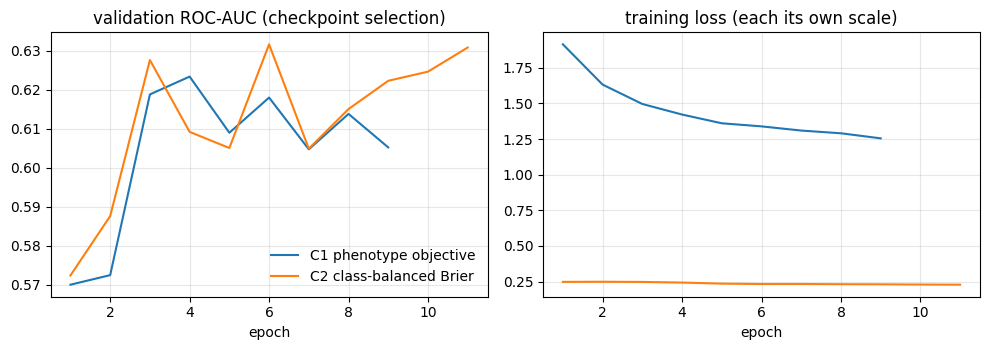

In [26]:
# 15b. CLASSIFIER 2: ImageTokenClassifier trained with the class-balanced Brier loss
clsB, histB_cls = train_classifier('C2_brier', 'brier', seed=CLS_SEED + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for tag, h, color in [('C1 phenotype objective', histP, 'tab:blue'), ('C2 class-balanced Brier', histB_cls, 'tab:orange')]:
    if len(h): axes[0].plot(h.epoch, h.val_auc, color=color, label=tag); axes[1].plot(h.epoch, h.train_total, color=color)
axes[0].set_title('validation ROC-AUC (checkpoint selection)'); axes[1].set_title('training loss (each its own scale)')
for a in axes: a.set_xlabel('epoch'); a.grid(alpha=.3)
axes[0].legend(frameon=False); plt.tight_layout(); fig.savefig(RUN / 'classifier_training_curves.png', dpi=140); plt.show()

## 16. Validation: ensemble and thresholds

In [27]:
# 16. Validation predictions, ensemble and thresholds (everything is chosen here, on validation)
val_P = predict_classifier(clsP, val_loader_cls); val_B = predict_classifier(clsB, val_loader_cls)
assert (val_P.image_id.values == val_B.image_id.values).all()
val_E = val_P.copy(); val_E['prob'] = 0.5 * (val_P.prob.values + val_B.prob.values)
VAL_PRED = {'C1 pheno': val_P, 'C2 brier': val_B, 'C-ens': val_E}
THRESHOLDS = {name: choose_threshold_balanced_accuracy(d.label.values, d.prob.values) for name, d in VAL_PRED.items()}
val_table = pd.DataFrame([{'model': name, 'balanced_accuracy_at_t*': THRESHOLDS[name][1], **classification_metrics(d.label.values, d.prob.values, THRESHOLDS[name][0])}
                          for name, d in VAL_PRED.items()])
print('Validation metrics at the validation-chosen threshold t*:'); display(val_table.round(4)); val_table.to_csv(RUN / 'classification_validation_metrics.csv', index=False)

Validation metrics at the validation-chosen threshold t*:


,model,balanced_accuracy_at_t*,n,threshold,roc_auc,average_precision,sensitivity,specificity,f1,balanced_accuracy,brier,ece,tn,fp,fn,tp
0,C1 pheno,0.6225,462,0.38,0.6233,0.5595,0.8626,0.3825,0.6642,0.6225,0.2622,0.1472,96,155,29,182
1,C2 brier,0.6266,462,0.54,0.6316,0.5647,0.7393,0.5139,0.6380,0.6266,0.2410,0.0798,129,122,55,156
2,C-ens,0.6151,462,0.46,0.6325,0.5661,0.8199,0.4104,0.6504,0.6151,0.2423,0.0821,103,148,38,173


## 17. Test evaluation (once)

Test metrics (threshold from validation; ROC-AUC interval = patient-level bootstrap):


,model,n,threshold,roc_auc,average_precision,sensitivity,specificity,f1,balanced_accuracy,brier,ece,tn,fp,fn,tp,roc_auc_ci_low,roc_auc_ci_high
0,C1 pheno,478,0.38,0.6800,0.5535,0.8391,0.3849,0.5759,0.6120,0.2493,0.1862,117,187,28,146,0.6194,0.7380
1,C2 brier,478,0.54,0.6675,0.5220,0.7069,0.5526,0.5681,0.6298,0.2416,0.1581,168,136,51,123,0.6063,0.7269
2,C-ens,478,0.46,0.6858,0.5570,0.7989,0.4375,0.5744,0.6182,0.2354,0.1564,133,171,35,139,0.6261,0.7426


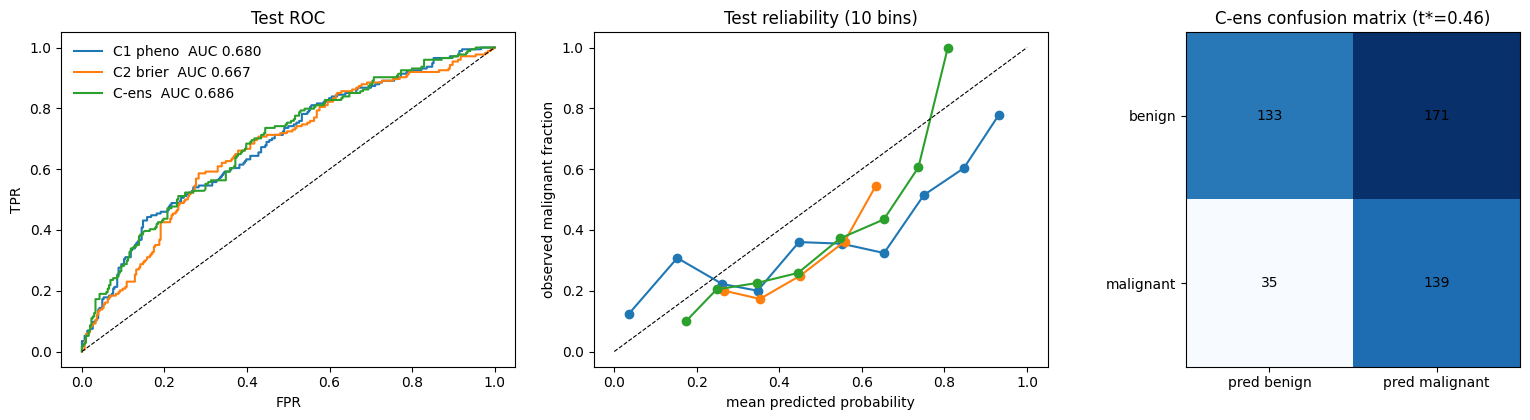

In [28]:
# 17. Held-out test evaluation (once), ROC curves, calibration, confusion matrices, bootstrap intervals
if RUN_TEST:
    test_P = predict_classifier(clsP, test_loader_cls); test_B = predict_classifier(clsB, test_loader_cls)
    assert (test_P.image_id.values == test_B.image_id.values).all()
    test_E = test_P.copy(); test_E['prob'] = 0.5 * (test_P.prob.values + test_B.prob.values)
    TEST_PRED = {'C1 pheno': test_P, 'C2 brier': test_B, 'C-ens': test_E}
    rows = []
    for name, d in TEST_PRED.items():
        lo, hi = patient_bootstrap_auc(d)
        rows.append({'model': name, **classification_metrics(d.label.values, d.prob.values, THRESHOLDS[name][0]), 'roc_auc_ci_low': lo, 'roc_auc_ci_high': hi})
        d.to_csv(RUN / f'classification_test_predictions_{name.split()[0]}.csv', index=False)
    test_table = pd.DataFrame(rows); test_table.to_csv(RUN / 'classification_test_metrics.csv', index=False)
    print('Test metrics (threshold from validation; ROC-AUC interval = patient-level bootstrap):'); display(test_table.round(4))

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    for name, color in [('C1 pheno', 'tab:blue'), ('C2 brier', 'tab:orange'), ('C-ens', 'tab:green')]:
        d = TEST_PRED[name]; fpr, tpr, _ = roc_curve(d.label, d.prob); axes[0].plot(fpr, tpr, color=color, label=f'{name}  AUC {safe_auc(d.label, d.prob):.3f}')
        edges = np.linspace(0, 1, ECE_BINS + 1); mids, obs = [], []
        for i in range(ECE_BINS):
            m = (d.prob >= edges[i]) & (d.prob <= edges[i + 1] if i == ECE_BINS - 1 else d.prob < edges[i + 1])
            if m.any(): mids.append(d.prob[m].mean()); obs.append(d.label[m].mean())
        axes[1].plot(mids, obs, marker='o', color=color, label=name)
    axes[0].plot([0, 1], [0, 1], 'k--', lw=.8); axes[0].set_title('Test ROC'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].legend(frameon=False)
    axes[1].plot([0, 1], [0, 1], 'k--', lw=.8); axes[1].set_title('Test reliability (10 bins)'); axes[1].set_xlabel('mean predicted probability'); axes[1].set_ylabel('observed malignant fraction')
    cm = np.array([[test_table.loc[test_table.model == 'C-ens', 'tn'].iloc[0], test_table.loc[test_table.model == 'C-ens', 'fp'].iloc[0]],
                   [test_table.loc[test_table.model == 'C-ens', 'fn'].iloc[0], test_table.loc[test_table.model == 'C-ens', 'tp'].iloc[0]]])
    axes[2].imshow(cm, cmap='Blues'); axes[2].set_title(f'C-ens confusion matrix (t*={THRESHOLDS["C-ens"][0]:.2f})')
    axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(['pred benign', 'pred malignant']); axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(['benign', 'malignant'])
    for (i, j), v in np.ndenumerate(cm): axes[2].text(j, i, int(v), ha='center', va='center', color='k')
    plt.tight_layout(); fig.savefig(RUN / 'classification_test_roc_calibration.png', dpi=140); plt.show()
else:
    print('RUN_TEST is False: test metrics were not computed.')

## 18. Summary artifacts

In [29]:
# 18. Summary artifacts
summary = {'localization': loc_summary.to_dict('records'), 'localization_selected': {k: dict(sigma=v[0], dice_threshold=v[1]) for k, v in loc_chosen.items()},
           'classification_validation': val_table.to_dict('records'), 'thresholds_balanced_accuracy': {k: v[0] for k, v in THRESHOLDS.items()}}
if RUN_TEST: summary['classification_test'] = test_table.to_dict('records')
json.dump(summary, open(RUN / 'summary.json', 'w'), indent=2, default=float)
torch.save({'locA': locA.state_dict(), 'locB': locB.state_dict(), 'ensemble_weights': ENSEMBLE_WEIGHTS, 'selected': loc_chosen}, RUN / 'localizers_A_B_ensemble.pt')
torch.save({'clsP': clsP.state_dict(), 'clsB': clsB.state_dict(), 'thresholds': {k: v[0] for k, v in THRESHOLDS.items()},
            'descriptor_cols': desc_cols, 'attribute_sizes': attribute_sizes}, RUN / 'classifiers_pheno_brier.pt')
print('Saved everything to', RUN)
display(loc_summary.round(4))
if RUN_TEST: display(test_table.round(4))

Saved everything to /content/drive/MyDrive/mammo_semcom_work/runs/dual_loss_ensemble_v1


,variant,split,n_images,hit_at_1_raw,sigma_star,hit_rate,hit_ci_low,hit_ci_high,dice_threshold,dice
0,A,val,465,0.1785,12,0.2043,0.1701,0.2433,0.5,0.0889
1,A,test,482,0.1805,12,0.2012,0.1679,0.2393,0.5,0.1015
2,B,val,465,0.2989,8,0.3462,0.3044,0.3906,0.9,0.1252
3,B,test,482,0.2822,8,0.3382,0.2974,0.3815,0.9,0.1329
4,ENS,val,465,0.2645,8,0.3441,0.3023,0.3884,0.7,0.1261
5,ENS,test,482,0.2510,8,0.3174,0.2775,0.3603,0.7,0.1304


,model,n,threshold,roc_auc,average_precision,sensitivity,specificity,f1,balanced_accuracy,brier,ece,tn,fp,fn,tp,roc_auc_ci_low,roc_auc_ci_high
0,C1 pheno,478,0.38,0.6800,0.5535,0.8391,0.3849,0.5759,0.6120,0.2493,0.1862,117,187,28,146,0.6194,0.7380
1,C2 brier,478,0.54,0.6675,0.5220,0.7069,0.5526,0.5681,0.6298,0.2416,0.1581,168,136,51,123,0.6063,0.7269
2,C-ens,478,0.46,0.6858,0.5570,0.7989,0.4375,0.5744,0.6182,0.2354,0.1564,133,171,35,139,0.6261,0.7426


## 19. Interpretation and limitations
- **Two localizers, one recipe.** A (CLEAN_V2) and B (size-balanced multiscale squared error) share architecture, optimizer, epochs, early stopping and checkpoint rule; only the loss differs (B uses seed + 1 and, unless `LOC_B_INIT_FROM_A=True`, starts from scratch). The ensemble is a probability-level average, so any gain comes from complementary errors; check the A/B agreement table before claiming it.
- **Hit rate.** hit@1 uses the raw arg-max of the union map; the smoothed hit rate uses a validation-chosen sigma. Both use the 24-px dilated mask, which is generous for tiny calcifications. Validation and test have different lesion-size distributions in CBIS-DDSM-derived splits, so a validation-to-test drop is expected; report Wilson intervals (given) rather than point values alone.
- **Loss B has no peak term and no explicit positive weighting.** It balances lesion sizes but a squared error on sigmoid outputs can saturate; hit rate may therefore be lower or higher than A. This is an empirical question answered by the table, not a design guarantee.
- **Classifier input.** The ImageTokenClassifier consumes the *predicted* localization statistics of the ensemble, so the classification results are end-to-end with respect to localization (no annotation centring). For training images the localizers have seen the masks, so their statistics are cleaner than on validation or test. Out-of-fold localizers would remove this optimism; it is the main remaining leakage-like effect.
- **Image-level labels.** Missing or mixed image-level diagnoses are excluded. C1 (phenotype objective) is trained only on images that occur in at least one collision pair; C2 (Brier) sees every training image. Phenotype descriptors are used only when all lesions of an image agree, and pairs only for single-type images; the phenotype objective is therefore an image-level adaptation of the lesion-level objective of the uploaded notebook. In the figure's architecture the phenotype embedding u is the projected mean of the four latent tokens and the diagnostic embedding v is the normalised hidden layer of the output head; the logit is taken from the un-normalised hidden layer.
- **Class-balanced Brier loss.** Batch size is two, so balancing is only within each tiny batch, and class-balanced training does not give probabilities calibrated to the original class distribution. Calibration (Brier score, ECE, reliability curve) is reported separately and Brier score reflects more than calibration alone. The loss is not claimed to be novel.
- **ROC-AUC** is an evaluation and checkpoint-selection metric, not optimised directly. The column `average_precision` is AP, not a trapezoidal PR-AUC. The threshold t* maximises validation balanced accuracy and is applied unchanged to test.
- **Statistics.** Test sets are small; the bootstrap interval for ROC-AUC is patient-level. Differences between A, B, ENS (or C1, C2, C-ens) of about 0.02 hit rate or AUC are within sampling noise unless the intervals clearly separate; one seed per model was trained.
- This notebook was assembled from the uploaded notebook and the supplied specifications and was syntax-checked, but it has not been executed on your data or GPU. Run the registration audit first and inspect the overlays.